This file is for analyzing the results of GRMHD simulations. All analysis is finished and saved in the folder. If you want to rerun the analysis, please set RERUN_ANALYSIS = True.


What is needed:

-   `GRMHD/data/grmhdDataOrigin.npy` GRMHD simulation data of different time and different axion fields. Which axion alpha=0.3
-   `GRMHD/data/different_omega/` GRMHD simulation data of different axion omega.


What is generated:

-   `GRMHD/grmhdDataAfterImageS.npy` GRMHD simulation data of different time and different axion fields after processing like blurring, ...
-   `EVPA.npy` EVPA data calculated from the different time and different axion fields GRMHD data
-   `EVPA_1d.npy` EVPA data integrated over radius with 10 degree average
-   `EVPA_result.npy` Axion fields effection of EVPA of different axion omega
-   `EVPA_phi_10deg_result.npy` Axion fields effection of EVPA of different axion omega, integrated over radius with 10 degree average
-   `EVPA_fit_result.npy` Axion fields effection of EVPA of different time
-   `EVPA_fit_result_1d.npy` Axion fields effection of EVPA of different time, integrated over radius with 10 degree average


In [1]:
RERUN_ANALYSIS = False

In [2]:
RERUN_ANALYSIS = True

In [3]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import sys
from copy import deepcopy
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background, plot_quivers, CircleCalc, ImageS
from utils.raytracing import calculate_source_position
from scipy.optimize import curve_fit

Load the GRMHD data. The shape of grmhdDataOrigin is (Num, 17, 400, 400, 4):

-   Num: Number of simulations of different time. Time step is $0.1 R_g$
-   17: 0 is the simulation without axion field, 1-16 are the simulation with axion field phases from 0 to $2\pi \frac{15}{16}$
-   400x400: simulation result image is 400x400
-   4: I, Q, U, V


In [4]:
def getGRMHDDataAfterImageS(
    grmhdDataOrigin,
    rotation_angle=0.6 * np.pi,
    gaussian_kernel=None,
    init_fov=46.2262,
    final_shape=64,
    image_mask=1,
    oneD_coord=None,
    oneD_method=1,
    final_fov=32.6868,
):
    """
    ImageS blurs the data image, and calculates many useful quantities. This function calculates all the data at once.
    """
    shape = grmhdDataOrigin.shape
    shape = (shape[0], shape[1], final_shape, final_shape, 4)
    grmhdDataAfterImageS = np.zeros(shape)
    EVPA = np.zeros((shape[0], shape[1], final_shape, final_shape))
    EVPA_1d = np.zeros((shape[0], shape[1], 360))
    EVPA_1d_10deg = np.zeros((shape[0], shape[1], 360))
    for t in range(shape[0]):
        print(t)
        for i in range(shape[1]):
            tmp = ImageS(
                grmhdDataOrigin[t, i],
                rotation_angle=rotation_angle,
                gaussian_kernel=gaussian_kernel,
                init_fov=init_fov,
                final_shape=final_shape,
                mask=image_mask,
                final_fov=final_fov,
                calc_1D=(oneD_coord is None),
            )
            grmhdDataAfterImageS[t, i, :, :, 0] = tmp.I
            grmhdDataAfterImageS[t, i, :, :, 1] = tmp.Q
            grmhdDataAfterImageS[t, i, :, :, 2] = tmp.U
            grmhdDataAfterImageS[t, i, :, :, 3] = tmp.V
            EVPA[t, i] = tmp.evpa / 180 * np.pi  # rad
            if oneD_coord is None:
                EVPA_1d[t, i] = np.roll(
                    tmp.evpa_phi / 180 * np.pi, -90
                )  # rad 从pcolormesh显示的顶端（y轴正向）逆时针算起的
                EVPA_1d_10deg[t, i] = np.roll(
                    tmp.evpa_phi_10deg / 180 * np.pi, -90
                )  # rad 从pcolormesh显示的顶端（y轴正向）逆时针算起的
            else:
                if oneD_method == 1:
                    EVPA_1d[t, i] = tmp.EVPA_1d_from_coord(
                        oneD_coord
                    )  # 从pcolormesh显示的顶端（y轴正向）逆时针算起的
                    EVPA_1d_10deg[t, i] = EVPA_1d[t, i]
                elif oneD_method == 2:
                    EVPA_1d[t, i] = tmp.EVPA_1d_from_coord_2(
                        oneD_coord
                    )  # 从pcolormesh显示的顶端（y轴正向）逆时针算起的
                    EVPA_1d_10deg[t, i] = EVPA_1d[t, i]

    return grmhdDataAfterImageS, EVPA, EVPA_1d, EVPA_1d_10deg

This will cost long time, so we save the data in a file, you can load it directly.


In [5]:
if RERUN_ANALYSIS:
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        _grmhd_data_origin = np.load(
            f"data_in/GRMHD_Data_1600-3000_alpha={alpha}_res=100.npy"
        )
        _grmhdDataAfterImageS, _EVPA, _EVPA_1d, _EVPA_1d_10deg = (
            getGRMHDDataAfterImageS(_grmhd_data_origin)
        )
        np.save(
            f"data_out/grmhdDataAfterImageS_alpha={alpha}_res=100.npy",
            _grmhdDataAfterImageS,
        )
        np.save(f"data_out/EVPA_alpha={alpha}_res=100.npy", _EVPA)
        np.save(f"data_out/EVPA_1d_alpha={alpha}_res=100.npy", _EVPA_1d)
        np.save(f"data_out/EVPA_1d_10deg_alpha={alpha}_res=100.npy", _EVPA_1d_10deg)

    for alpha in [0.3]:
        _grmhd_data_origin = np.load(
            f"data_in/GRMHD_Data_1600-3000_alpha={alpha}_res=400.npy"
        )
        _grmhdDataAfterImageS, _EVPA, _EVPA_1d, _EVPA_1d_10deg = (
            getGRMHDDataAfterImageS(_grmhd_data_origin)
        )
        np.save(
            f"data_out/grmhdDataAfterImageS_alpha={alpha}_res=400.npy",
            _grmhdDataAfterImageS,
        )
        np.save(f"data_out/EVPA_alpha={alpha}_res=400.npy", _EVPA)
        np.save(f"data_out/EVPA_1d_alpha={alpha}_res=400.npy", _EVPA_1d)
        np.save(f"data_out/EVPA_1d_10deg_alpha={alpha}_res=400.npy", _EVPA_1d_10deg)

0
1


KeyboardInterrupt: 

In [6]:
grmhdDataAfterImageS = {}
EVPA = {}
EVPA_1d = {}
EVPA_1d_10deg = {}

for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
    grmhdDataAfterImageS[alpha] = np.load(
        f"data_out/grmhdDataAfterImageS_alpha={alpha}_res=100.npy"
    )
    EVPA[alpha] = np.load(f"data_out/EVPA_alpha={alpha}_res=100.npy")
    EVPA_1d[alpha] = np.load(f"data_out/EVPA_1d_alpha={alpha}_res=100.npy")
    EVPA_1d_10deg[alpha] = np.load(f"data_out/EVPA_1d_10deg_alpha={alpha}_res=100.npy")

grmhdDataAfterImageS_400 = {}
EVPA_400 = {}
EVPA_400_1d = {}
EVPA_400_1d_10deg = {}

for alpha in [0.3]:
    grmhdDataAfterImageS_400[alpha] = np.load(
        f"data_out/grmhdDataAfterImageS_alpha={alpha}_res=400.npy"
    )
    EVPA_400[alpha] = np.load(f"data_out/EVPA_alpha={alpha}_res=400.npy")
    EVPA_400_1d[alpha] = np.load(f"data_out/EVPA_1d_alpha={alpha}_res=400.npy")
    EVPA_400_1d_10deg[alpha] = np.load(
        f"data_out/EVPA_1d_10deg_alpha={alpha}_res=400.npy"
    )

Plot an average image:


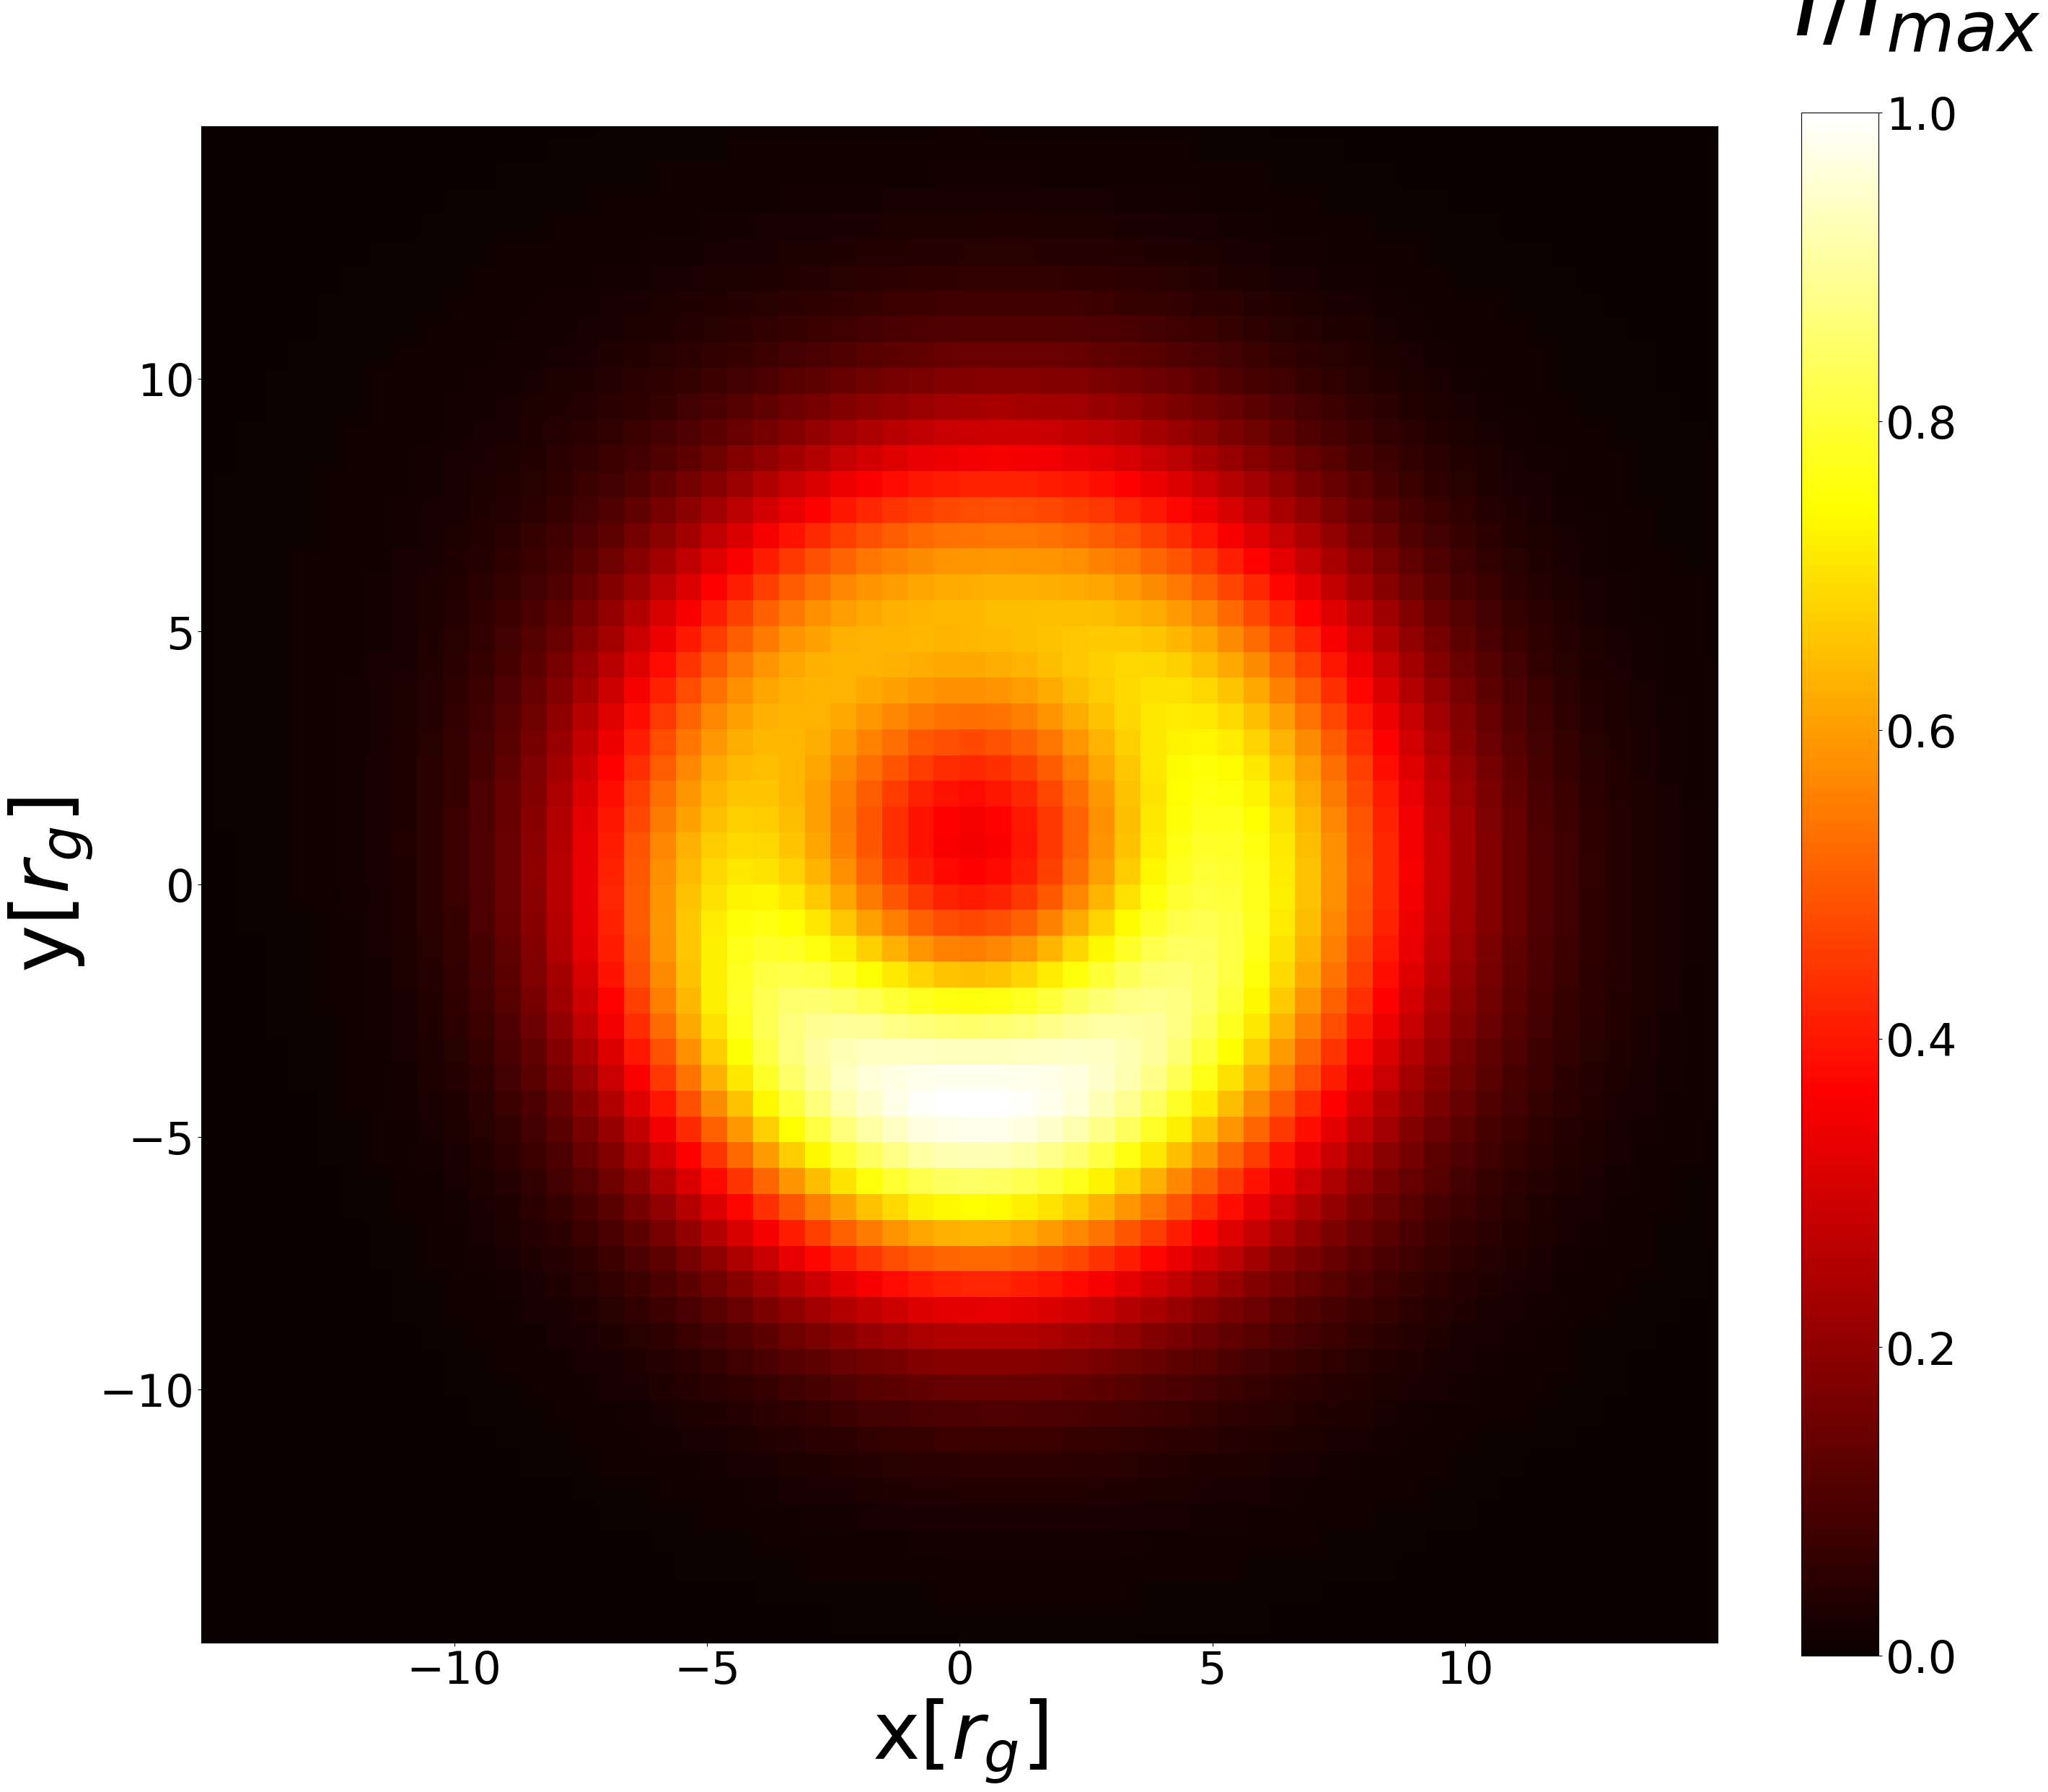

In [ ]:
figure, ax0 = plt.subplots(figsize=(30, 30))
ax0.set_xlim(-15, 15)
ax0.set_xlabel("x[$r_g$]", size=80)
ax0.set_ylim(-15, 15)
ax0.set_ylabel("y[$r_g$]", size=80)
plt.tick_params(labelsize=45)
plt.xticks([-10, -5, 0, 5, 10])
plt.yticks([-10, -5, 0, 5, 10])
Plot_Background(figure, ax0, np.sum(grmhdDataAfterImageS[0.3][:, 0, :, :, 0], axis=0))
figure.show()

Some functions:


In [7]:
# def fit_cos(x):
#     if np.isnan(x).any():
#         return np.nan
#     initial_guess = [0]
#     # using curve_fit to fit the data
#     popt, pcov = curve_fit(
#         lambda wt, phi: np.cos(wt + phi),
#         np.linspace(0, 2 * np.pi - np.pi / 8, 16),
#         x,
#         p0=initial_guess,
#     )
#     # print(pcov)
#     # popt[0] is phi
#     phi_fit = popt[0]
#     return phi_fit

from utils.libanaly import move_evpa_to_center


def estimate_cos_params(cos_data, evpa_angle=False):
    if cos_data.shape[0] == 17:
        data_16 = cos_data[1:]
    elif cos_data.shape[0] == 16:
        data_16 = cos_data

    if evpa_angle:
        new_cos_data = np.apply_along_axis(move_evpa_to_center, 0, data_16)
    else:
        new_cos_data = data_16

    N = 16
    X = np.sum(
        new_cos_data
        * np.exp(-2j * np.pi * np.arange(N) / N).reshape(
            -1, *[1] * (new_cos_data.ndim - 1)
        ),
        axis=0,
    )
    A = 2 * np.abs(X) / N
    phi = np.angle(X)
    phi = (phi + np.pi) % (2 * np.pi) - np.pi

    return A, phi


def fit_cos_evpa(evpa_list):
    """
    This function fits the EVPA data to a cosine function. The output shape is input shape removed the first dimension.
    """

    # evpa_list: 17,resolution,resolution or 17,360
    tEVPA = CircleCalc.circle_sub_evpa(evpa_list[1:], evpa_list[0]) + evpa_list[0]
    average_EVPA = np.mean(tEVPA, axis=0)
    average_EVPA = ((average_EVPA + np.pi / 2) % np.pi) - np.pi / 2
    delta_evpa_list = CircleCalc.circle_sub_evpa(evpa_list[1:], average_EVPA)
    A, phi = estimate_cos_params(delta_evpa_list)
    return A, phi, average_EVPA


def Fit_EVPA_different_omega():
    dirname = "data_in/different_omega"
    # 寻找dirname内的所有文件夹
    folders = [
        f for f in os.listdir(dirname) if os.path.isdir(os.path.join(dirname, f))
    ]
    # 遍历每个文件夹
    for folder in folders:
        print(folder)
        # 获取文件夹路径
        folder_path = os.path.join(dirname, folder)
        originData = np.load(os.path.join(folder_path, "result.npy"))
        # originData.shape=(17, 100, 100, 4)
        # get EVPA
        EVPA = np.zeros((17, 64, 64))
        EVPA_phi_10deg = np.zeros((17, 360))

        for i in range(17):
            tmp = ImageS(originData[i])
            EVPA[i, :, :] = tmp.evpa / 180 * np.pi
            EVPA_phi_10deg[i, :] = tmp.evpa_phi_10deg / 180 * np.pi
        # fit EVPA
        A, phi, average_EVPA = fit_cos_evpa(EVPA)  # rad,rad,rad
        res1 = np.zeros((64, 64, 3))
        res1[:, :, 0] = A
        res1[:, :, 1] = phi
        res1[:, :, 2] = average_EVPA
        A, phi, average_EVPA = fit_cos_evpa(EVPA_phi_10deg)  # rad,rad,rad
        res2 = np.zeros((360, 3))
        res2[:, 0] = A
        res2[:, 1] = phi
        res2[:, 2] = average_EVPA
        # save result
        np.save(os.path.join(folder_path, "EVPA_result.npy"), res1)
        np.save(os.path.join(folder_path, "EVPA_phi_10deg_result.npy"), res2)


def Fit_EVPA_different_omega():
    for alpha in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.44]:
        print(alpha)
        res1 = np.zeros((EVPA[alpha].shape[0], 64, 64, 3))
        res2 = np.zeros((EVPA_1d_10deg[alpha].shape[0], 360, 3))
        for i in range(EVPA[alpha].shape[0]):
            print(i)
            A, phi, average_EVPA = fit_cos_evpa(EVPA[alpha][i])  # rad,rad,rad
            res1[i, :, :, 0] = A
            res1[i, :, :, 1] = phi
            res1[i, :, :, 2] = average_EVPA
            A, phi, average_EVPA = fit_cos_evpa(EVPA_1d_10deg[alpha][i])  # rad,rad,rad
            res2[i, :, 0] = A
            res2[i, :, 1] = phi
            res2[i, :, 2] = average_EVPA
        np.save(f"data_out/EVPA_cos_fit_result_alpha={alpha}.npy", res1)
        np.save(f"data_out/EVPA_cos_fit_result_1d_10deg_alpha={alpha}.npy", res2)

In [8]:
def process_alpha_0_3_res_400():
    for alpha in [0.3]:
        _grmhd_data_origin = np.load(
            f"data_in/GRMHD_Data_1600-3000_alpha={alpha}_res=400.npy"
        )
        _grmhdDataAfterImageS, _EVPA, _EVPA_1d, _EVPA_1d_10deg = (
            getGRMHDDataAfterImageS(_grmhd_data_origin, final_shape=256)
        )
        res1 = np.zeros((_EVPA.shape[0], 256, 256, 3))
        for i in range(_EVPA.shape[0]):
            print(i)
            A, phi, average_EVPA = fit_cos_evpa(_EVPA[i])  # rad,rad,rad
            res1[i, :, :, 0] = A
            res1[i, :, :, 1] = phi
            res1[i, :, :, 2] = average_EVPA
        np.save(f"data_out/EVPA_cos_fit_result_alpha={alpha}_final_shape=256.npy", res1)

This creates cosine fit result for simulations of different omega. (20min)
If you want to run this block, change False to True


In [9]:
# 20min
if RERUN_ANALYSIS:
    Fit_EVPA_different_omega()

0.1
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
0.15
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
0.2
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29

In [10]:
if RERUN_ANALYSIS:
    process_alpha_0_3_res_400()

0


KeyboardInterrupt: 

This creates cosine fit result for simulations of different time. You can load the data directly.


In [ ]:
# def get_EVPA_fit_result(EVPA):
#     shape = EVPA.shape
#     res = np.zeros((shape[0], shape[2], shape[3], 3))
#     for i in range(shape[0]):
#         print(i)
#         res[i, :, :, 0], res[i, :, :, 1], res[i, :, :, 2] = fit_cos_evpa(
#             EVPA[i, :, :, :]
#         )
#     return res

In [ ]:
# if RERUN_ANALYSIS:
#     EVPA_fit_result = get_EVPA_fit_result(EVPA)
#     np.save("EVPA_fit_result.npy", EVPA_fit_result)

In [ ]:
# EVPA_fit_result = np.load("EVPA_fit_result.npy")

This creates cosine fit result for simulations of different time, but it is 1d EVPA.


In [ ]:
# def get_EVPA_fit_result_1d(EVPA):
#     shape = EVPA.shape
#     res = np.zeros((shape[0], shape[2], 3))
#     for i in range(shape[0]):
#         print(i)
#         res[i, :, 0], res[i, :, 1], res[i, :, 2] = fit_cos_evpa(EVPA[i, :, :])
#     return res

In [ ]:
# if RERUN_ANALYSIS:
#     EVPA_fit_result_1d = get_EVPA_fit_result_1d(EVPA_1d)
#     np.save("EVPA_fit_result_1d.npy", EVPA_fit_result_1d)

In [ ]:
# EVPA_fit_result_1d = np.load("EVPA_fit_result_1d.npy")

This creates analytical result for 1d


In [11]:
filename = "../NormR.csv"

import csv

# 打开CSV文件并读取
with open(filename, mode="r") as file:
    reader = csv.reader(file)
    data = list(reader)  # 将CSV内容读入到一个列表中

    alpha_values = []
    r_values = []
    R_values = []

    # 解析CSV内容
    for row in data:
        alpha_values.append(float(row[0]))  # 第一列：alpha值
        r_values.append(float(row[1]))  # 第二列：r值
        R_values.append(float(row[2]))  # 第三列：R值

    # 将数据转换为numpy数组
    alpha_values = np.array(alpha_values)
    r_values = np.array(r_values)
    R_values = np.array(R_values)

    # 每一组（alpha, r）应该对应一个R值
    alpha_indices = np.unique(alpha_values)
    r_indices = np.unique(r_values)

    R_data = np.zeros((len(alpha_indices), len(r_indices), 3))
    R_data[:, :, 0] = alpha_values.reshape(len(alpha_indices), len(r_indices))
    R_data[:, :, 1] = r_values.reshape(len(alpha_indices), len(r_indices))
    R_data[:, :, 2] = R_values.reshape(len(alpha_indices), len(r_indices))


def get_R_interp_function(alpha_target, R_data):
    """
    从 R_data 中读取 alpha=alpha_target 时对应的 R 与 r 的关系，然后线性插值成一个函数，返回该函数。

    参数:
      alpha_target: float, 想要查找的 alpha 值
      R_data: numpy 数组，形状为 (num_alpha, num_r, 3)，其中:
              R_data[:,:,0] 为 alpha 值,
              R_data[:,:,1] 为 r 值,
              R_data[:,:,2] 为 R 值

    返回:
      一个函数 f(r)，利用线性插值计算给定 r 值对应的 R 值
    """
    import numpy as np
    from scipy.interpolate import interp1d

    # 每一行的alpha值相同，取第0列即可
    alphas = R_data[:, 0, 0]

    # 查找与给定 alpha_target 接近的行索引
    idx = np.where(np.isclose(alphas, alpha_target))[0]
    if len(idx) == 0:
        raise ValueError(f"在 R_data 中未找到 alpha = {alpha_target} 对应的数据")

    # 获取该行对应的 r 和 R 值
    row_data = R_data[idx[0], :, :]
    r_values = row_data[:, 1]
    R_values = row_data[:, 2]

    # 使用线性插值生成函数，允许外插
    f = interp1d(r_values, R_values, kind="linear", fill_value="extrapolate")
    return f

In [ ]:
# _grmhdDataAfterImageS,_EVPA,_EVPA_1d=getGRMHDDataAfterImageS(grmhdDataOrigin,gaussian_kernel=0)
# np.save("grmhdDataAfterImageS_no_blur.npy",_grmhdDataAfterImageS)
# np.save("EVPA_no_blur.npy",_EVPA)
# np.save("EVPA_1d_no_blur.npy",_EVPA_1d)
_grmhdDataAfterImageS = np.load("grmhdDataAfterImageS_no_blur.npy")
_EVPA = np.load("EVPA_no_blur.npy")
_EVPA_1d = np.load("EVPA_1d_no_blur.npy")

In [12]:
# create a (100,100,4)


def _r_trace(x, y):
    return np.sqrt(x**2 + y**2 / np.cos(17 / 180 * np.pi) ** 2)


def _omega(alpha):
    return alpha * (1 - alpha**2 / 2 / (2 + 1 + 1) ** 2)


def _phi_trace(x, y):
    return np.arctan2(y / np.cos(17 / 180 * np.pi), x)


def _phase_trace(x, y):
    return -_phi_trace(x, y) + _omega(0.3) * _r_trace(x, y) * np.cos(
        _phi_trace(x, y)
    ) * np.sin(17 / 180 * np.pi)


def _axion_field_old(x, y, R, wt):
    return 0.1 / 2 / np.pi * R(_r_trace(x, y)) * np.cos(_phase_trace(x, y) + wt)


_R = get_R_interp_function(0.3, R_data)


x_coords = np.tile(np.linspace(-49.5, 49.5, 100), (100, 1)) * 46.2262 / 99
y_coords = (
    np.tile(np.linspace(-49.5, 49.5, 100).reshape(100, 1), (1, 100)) * 46.2262 / 99
)
from functools import lru_cache


@lru_cache(maxsize=None)  # None 表示无限缓存
def _calculate_source_position(x, y):
    print("1")
    obs_rho = np.sqrt(x**2 + y**2)
    obs_phi = np.arctan2(x, y)  # 特别注意这个phi是和y轴的夹角，顺时针增大
    try:
        return calculate_source_position(
            obs_rho=obs_rho,
            obs_phi=obs_phi,
            r_o=500,
            theta_o=17 / 180 * np.pi,
            a=-0.9375,
            # a=0,
            M=1.0,
        )  # phi_s又是逆时针的)
    except Exception as e:
        print(e)
        return (200.0, 0.0, 0.0)


_v_calculate_source_position = np.vectorize(_calculate_source_position)


def _axion_field(x, y, R, wt):
    r_s, phi_s, t_s = _v_calculate_source_position(x, y)
    _phase = -phi_s + _omega(0.3) * t_s
    return 0.1 / 2 / np.pi * R(r_s) * np.cos(_phase + wt)


def _fit_cos_evpa_A_only(evpa_list):
    """
    This function fits the EVPA data to a cosine function. The output shape is input shape removed the first dimension.
    """

    # evpa_list: 17,resolution,resolution or 17,360
    tEVPA = CircleCalc.circle_sub_evpa(evpa_list[1:], evpa_list[0]) + evpa_list[0]
    average_EVPA = np.mean(tEVPA, axis=0)
    average_EVPA[average_EVPA < -np.pi / 2] += np.pi
    average_EVPA[average_EVPA > np.pi / 2] -= np.pi
    if evpa_list.shape[0] == 16:
        delta_evpa_list = CircleCalc.circle_sub_evpa(evpa_list, average_EVPA)
    elif evpa_list.shape[0] == 17:
        delta_evpa_list = CircleCalc.circle_sub_evpa(evpa_list[1:], average_EVPA)
    A = np.sqrt((delta_evpa_list**2).sum(axis=0) / 8)
    # phi=np.apply_along_axis(fit_cos, axis=0, arr=delta_evpa_list/A)
    return A


def _scale_evpa(evpa_list, scale_factor):
    res = np.zeros(evpa_list.shape)
    tEVPA = CircleCalc.circle_sub_evpa(evpa_list[1:], evpa_list[0]) + evpa_list[0]
    average_EVPA = np.mean(tEVPA, axis=0)
    average_EVPA = (average_EVPA + np.pi / 2) % np.pi - np.pi / 2
    if evpa_list.shape[0] == 16:
        delta_evpa_list = CircleCalc.circle_sub_evpa(evpa_list, average_EVPA)
        res = (
            average_EVPA + delta_evpa_list * scale_factor + np.pi / 2
        ) % np.pi - np.pi / 2
    elif evpa_list.shape[0] == 17:
        delta_evpa_list = CircleCalc.circle_sub_evpa(evpa_list[1:], average_EVPA)
        res[0] = average_EVPA
        res[1:] = (
            average_EVPA + delta_evpa_list * scale_factor + np.pi / 2
        ) % np.pi - np.pi / 2
    return res

In [ ]:
# analytical_data=np.zeros((141,17,100,100,4))
# _GRMHD_EVPA_mean=0.5* np.arctan2(grmhdDataOrigin[:,0,:,:,2].mean(axis=0),grmhdDataOrigin[:,0,:,:,1].mean(axis=0)) # rad
# _GRMHD_P_mean=np.sqrt(grmhdDataOrigin[:,0,:,:,1].mean(axis=0)**2 + grmhdDataOrigin[:,0,:,:,2].mean(axis=0)**2) # P mean

# for g in range(141):
#     _tmp_EVPA=0.5* np.arctan2(grmhdDataOrigin[g,0,:,:,2],grmhdDataOrigin[g,0,:,:,1])
#     _tmp_P=np.sqrt(grmhdDataOrigin[g,0,:,:,1]**2 + grmhdDataOrigin[g,0,:,:,2]**2)
#     for i in range(17):
#         analytical_data[g,i,:,:,0]=grmhdDataOrigin[g,0,:,:,0]
#         if i==0:
#             _GRMHD_EVPA_plus_Axion=_tmp_EVPA
#         else:
#             wt=2*np.pi/16*i
#             _GRMHD_EVPA_plus_Axion=_tmp_EVPA + _axion_field(x_coords,y_coords,_R,wt)
#         analytical_data[g,i,:,:,1]=np.cos(2*_GRMHD_EVPA_plus_Axion)*_tmp_P
#         analytical_data[g,i,:,:,2]=np.sin(2*_GRMHD_EVPA_plus_Axion)*_tmp_P

# analytical_data_after_imageS,analytical_EVPA_after_imageS,analytical_EVPA_after_imageS_1d=getGRMHDDataAfterImageS(analytical_data,gaussian_kernel=0)

# _analytical_A=np.array([_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[g]) for g in range(141)])
# np.save("data/analytical_A_no_blur.npy",_analytical_A)

# analytical_data_after_imageS,analytical_EVPA_after_imageS,analytical_EVPA_after_imageS_1d=getGRMHDDataAfterImageS(analytical_data)
# _analytical_A=np.array([_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[g]) for g in range(141)])
# np.save("data/analytical_A.npy",_analytical_A)

In [ ]:
# _analytical_A_no_blur=np.load("data_in/analytical_A_no_blur.npy")
# _analytical_A=np.load("data_in/analytical_A.npy")

In [ ]:
# _tmp=np.zeros((141,360))
# for i in range(141):
#     _tmp[i]=_fit_cos_evpa_A_only(_EVPA_1d[i])

In [ ]:
# r_s_coords,_,_=_v_calculate_source_position(x_coords, y_coords)

In [13]:
def get_analytical_evpa(
    grmhddata,
    axion_field_coord,
    image_mask=1,
    init_fov=46.2262,
    # phi_average=True,
    gaussian_kernel=None,
    rotation_angle=0.6 * np.pi,
    oneD_coord=None,
    final_shape=64,
    oneDmethod=1,
):
    _res = grmhddata.shape[1]
    analytical_data_fake = np.zeros((17, _res, _res, 4))
    _tmp_EVPA = 0.5 * np.arctan2(grmhddata[0, :, :, 2], grmhddata[0, :, :, 1])
    _tmp_P = np.sqrt(grmhddata[0, :, :, 1] ** 2 + grmhddata[0, :, :, 2] ** 2)
    analytical_data_fake[:, :, :, 0] = grmhddata[:, :, :, 0]
    for i in range(17):
        if i == 0:
            _GRMHD_EVPA_plus_Axion = _tmp_EVPA
        else:
            wt = 2 * np.pi / 16 * i
            # _GRMHD_EVPA_plus_Axion=_tmp_EVPA + _axion_field_old(x_coords,y_coords,_R,wt)
            _GRMHD_EVPA_plus_Axion = _tmp_EVPA + axion_field_coord[i - 1]
        analytical_data_fake[i, :, :, 1] = np.cos(2 * _GRMHD_EVPA_plus_Axion) * _tmp_P
        analytical_data_fake[i, :, :, 2] = np.sin(2 * _GRMHD_EVPA_plus_Axion) * _tmp_P

    return getGRMHDDataAfterImageS(
        analytical_data_fake[np.newaxis, ...],
        init_fov=init_fov,
        # phi_average=phi_average,
        gaussian_kernel=gaussian_kernel,
        rotation_angle=rotation_angle,
        image_mask=image_mask,
        oneD_coord=oneD_coord,
        final_shape=final_shape,
        oneD_method=oneDmethod,
    )


def get_raptor_evpa(
    grmhddata,
    image_mask=1,
    init_fov=46.2262,
    final_fov=32.6868,
    # phi_average=True,
    gaussian_kernel=None,
    rotation_angle=0.6 * np.pi,
    oneD_coord=None,
    final_shape=64,
    oneDmethod=1,
):
    _grmhddata = deepcopy(grmhddata)
    return getGRMHDDataAfterImageS(
        _grmhddata[np.newaxis, ...],
        init_fov=init_fov,
        # phi_average=phi_average,
        gaussian_kernel=gaussian_kernel,
        rotation_angle=rotation_angle,
        image_mask=image_mask,
        oneD_coord=oneD_coord,
        final_shape=final_shape,
        oneD_method=oneDmethod,
        final_fov=final_fov,
    )


def get_analytical_evpa_vs_raptor(
    grmhddata, axion_field_coord, image_mask=1, init_fov=46.2262  # , phi_average=True
):
    _, _, EVPA1600fake_1d, _ = get_raptor_evpa(
        grmhddata, image_mask=image_mask, init_fov=init_fov  # , phi_average=phi_average
    )
    _, _, analytical_EVPA_fake_1d, _ = get_analytical_evpa(
        grmhddata,
        axion_field_coord,
        image_mask=image_mask,
        init_fov=init_fov,
        # phi_average=phi_average,
    )
    return EVPA1600fake_1d, analytical_EVPA_fake_1d


# 1d_evpa为逆时针

In [ ]:
# axion_field_coord=[_axion_field(x_coords,y_coords,_R,wt) for wt in np.linspace(0,2*np.pi-np.pi/8,16)]

In [ ]:
# plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(EVPA1600fake_1d[0])/np.pi*180,label='RAPTOR EVPA')
# plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(analytical_EVPA_fake_after_imageS_1d[0])/np.pi*180,label='Analytical EVPA')
# plt.legend()
# plt.ylim(0,1)
# plt.title("EVPA (gaussian kernel=2.17)")

lensed photon 加到下面的 1d 图上，修复方形的 bug


GRMHD 的 analytical 和 raptor 对比，让赤道面外的所有为 0，赤道面内除了 j 为 0. 同样对比 lensed photon 的结果 3. 打开全空间 j，等离子体效应仍然关闭 4. 全部打开


GRMHD: 2d: A 和 sigma ,phi 和 sigma_phi
1d: histogram of A, histogram of phi. gaussian/no gaussian


In [14]:
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Times New Roman"  # 设置正常文本的字体
plt.rcParams["mathtext.it"] = "Times New Roman:italic"  # 设置斜体文本的字体
plt.rcParams["mathtext.bf"] = "Times New Roman:bold"  # 设置粗体文本的字体
from matplotlib.ticker import FuncFormatter


def plot_evpa_r_and_a(
    grmhdData, axion_field_coord, r_coord, w_list=[4, 10], figsize=(8, 6), fontsize=20
):
    # title=r"EVPA ratio $\Theta_{\mathrm{RAPTOR}}/\Theta_{\mathrm{analytical}}$"
    title = r"EVPA ratio RAPTOR/Analytical"
    xlabel = r"Polar Angle $\phi$"
    ylabel = r"EVPA ratio"
    r_evpa = {}
    a_evpa = {}

    # 计算 w_list 对应的数据
    for w in w_list:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w] = 0
        r_s_coords[r_s_coords < w - 0.5] = 0
        r_s_coords[r_s_coords != 0] = 1
        r_evpa[w], a_evpa[w] = get_analytical_evpa_vs_raptor(
            grmhdData, axion_field_coord, image_mask=r_s_coords, init_fov=46.2262
        )

    # 计算 w=0 的数据
    r_s_coords = deepcopy(r_coord)
    r_s_coords[np.isnan(r_s_coords)] = 0
    r_s_coords[r_s_coords != 0] = 1
    r_evpa[0], a_evpa[0] = get_analytical_evpa_vs_raptor(
        grmhdData, axion_field_coord, image_mask=r_s_coords, init_fov=46.2262
    )

    # 创建新图像
    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(
        _fit_cos_evpa_A_only(r_evpa[0][0]) / _fit_cos_evpa_A_only(a_evpa[0][0]),
        label=r"$r \in [0, \infty)$",
    )
    for w in w_list:
        ax.plot(
            _fit_cos_evpa_A_only(r_evpa[w][0]) / _fit_cos_evpa_A_only(a_evpa[w][0]),
            label=rf"$r \in [{w-0.5}, {w}]$",
        )

    ax.set_xlim(0, 360)
    ax.set_xticks([0, 90, 180, 270, 360])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos: f"{int(val)}°"))
    # 设置标题和标签
    ax.set_title(title, fontsize=fontsize + 8)
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)

    # 加图例
    ax.legend(fontsize=fontsize)

    # 调整刻度字体大小
    ax.tick_params(axis="both", labelsize=fontsize)

    return fig, a_evpa

In [15]:
r_coord_path = "data_in/r_coord_400.npy"
r_coord = np.load(r_coord_path)
r_coord[np.isnan(r_coord)] = 0
axion_field_coord_path = "data_in/axion_field_coord_400_16.npy"
grmhd_data_paths = [
    "data_in/grmhdData2110_400_common.npy",
    "data_in/grmhdData2110_400_fake.npy",
    "data_in/grmhdData2110_400_eq_jonly.npy",
    "data_in/grmhdData2110_400_jonly.npy",
]
resolution = 400
fov = 46.2262
r_width = 0.5
photon_sphere = 2 * (1 + np.cos(2 / 3 * np.arccos(0.9375)))
axion_field_coord = np.load(axion_field_coord_path)

In [16]:
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import brentq

_tmp_coords = (
    np.linspace(-(resolution - 1) / 2, (resolution - 1) / 2, resolution)
    * fov
    / resolution
)

interp = RegularGridInterpolator(
    (_tmp_coords, _tmp_coords), _fit_cos_evpa_A_only(axion_field_coord)
)


def get_360_x_y(r_s):
    r_coord_path = "data_in/r_coord_400.npy"
    r_coord = np.load(r_coord_path)
    r_coord[np.isnan(r_coord)] = 0
    r_interp = RegularGridInterpolator((_tmp_coords, _tmp_coords), r_coord)
    res = np.zeros((360, 2))
    for i in range(360):
        varphi = i * np.pi / 180

        def r_func(_r):
            return r_interp((-_r * np.sin(varphi), _r * np.cos(varphi))) - r_s

        try:
            r_o = brentq(r_func, 0, 2 * r_s)
            res[i] = [-r_o * np.sin(varphi), r_o * np.cos(varphi)]
        except:
            res[i] = [np.nan, np.nan]
    return res


def get_analytical_A_1d(r_s):
    return np.interp(
        (np.linspace(0, 2 * np.pi, 360, endpoint=False) - 0.6 * np.pi) % (2 * np.pi),
        np.linspace(0, 2 * np.pi, 360, endpoint=False),
        interp(get_360_x_y(r_s)),
    )

In [17]:
analytical_A_1d = {}
analytical_A_1d[4] = get_analytical_A_1d(4)
analytical_A_1d[5] = get_analytical_A_1d(5)
analytical_A_1d[6] = get_analytical_A_1d(6)
analytical_A_1d[7] = get_analytical_A_1d(7)
analytical_A_1d[8] = get_analytical_A_1d(8)
analytical_A_1d[9] = get_analytical_A_1d(9)
analytical_A_1d[10] = get_analytical_A_1d(10)

In [18]:
get_360_x_y(9)[1]

array([-0.17347249,  9.93823232])

In [19]:
raptor_A_1d = {}
r_coord = np.load("data_in/r_coord_400.npy")
for grmhd_data_path in grmhd_data_paths:
    grmhddata = np.load(grmhd_data_path)
    raptor_A_1d[grmhd_data_path] = {}
    for w in [4, 5, 6, 7, 8, 9, 10]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _, _, _tmp_evpa_1d, _ = get_raptor_evpa(
            grmhddata,
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=0,
            oneD_coord=get_360_x_y(w),
            oneDmethod=1,
            rotation_angle=0,
        )
        raptor_A_1d[grmhd_data_path][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

    _, _, _tmp_evpa_1d, _ = get_raptor_evpa(grmhddata)
    raptor_A_1d[grmhd_data_path][0] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


In [20]:
# raptor_A_1d_blurred = {}
# r_coord = np.load("data_in/r_coord_400.npy")
_grmhd_data_origin = np.load(f"data_in/GRMHD_Data_1600-3000_alpha={0.3}_res=400.npy")
A_1d_r_9 = np.zeros((_grmhd_data_origin.shape[0], 360))
phi0_r_9 = np.zeros((_grmhd_data_origin.shape[0], 360))
for i in range(_grmhd_data_origin.shape[0]):
    print("i=", i)
    for w in [9]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _, _, _tmp_evpa_1d, _ = get_raptor_evpa(
            _grmhd_data_origin[i],
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=None,
            oneD_coord=get_360_x_y(w),
            oneDmethod=1,
            rotation_angle=0,
        )
        A_1d_r_9[i], phi0_r_9[i], _ = fit_cos_evpa(_tmp_evpa_1d[0])

np.save("data_out/A_1d_r=9_alpha=0.3_res=400.npy", A_1d_r_9)
np.save("data_out/phi0_1d_r=9_alpha=0.3_res=400.npy", phi0_r_9)

del i

i= 0
0
i= 1
0
i= 2
0
i= 3
0
i= 4
0
i= 5
0
i= 6
0
i= 7
0
i= 8
0
i= 9
0
i= 10
0
i= 11
0
i= 12
0
i= 13
0
i= 14
0
i= 15
0
i= 16
0
i= 17
0
i= 18
0
i= 19
0
i= 20
0
i= 21
0
i= 22
0
i= 23
0
i= 24
0
i= 25
0
i= 26
0
i= 27
0
i= 28
0
i= 29
0
i= 30
0
i= 31
0
i= 32
0
i= 33
0
i= 34
0
i= 35
0
i= 36
0
i= 37
0
i= 38
0
i= 39
0
i= 40
0
i= 41
0
i= 42
0
i= 43
0
i= 44
0
i= 45
0
i= 46
0
i= 47
0
i= 48
0
i= 49
0
i= 50
0
i= 51
0
i= 52
0
i= 53
0
i= 54
0
i= 55
0
i= 56
0
i= 57
0
i= 58
0
i= 59
0
i= 60
0
i= 61
0
i= 62
0
i= 63
0
i= 64
0
i= 65
0
i= 66
0
i= 67
0
i= 68
0
i= 69
0
i= 70
0
i= 71
0
i= 72
0
i= 73
0
i= 74
0
i= 75
0
i= 76
0
i= 77
0
i= 78
0
i= 79
0
i= 80
0
i= 81
0
i= 82
0
i= 83
0
i= 84
0
i= 85
0
i= 86
0
i= 87
0
i= 88
0
i= 89
0
i= 90
0
i= 91
0
i= 92
0
i= 93
0
i= 94
0
i= 95
0
i= 96
0
i= 97
0
i= 98
0
i= 99
0
i= 100
0
i= 101
0
i= 102
0
i= 103
0
i= 104
0
i= 105
0
i= 106
0
i= 107
0
i= 108
0
i= 109
0
i= 110
0
i= 111
0
i= 112
0
i= 113
0
i= 114
0
i= 115
0
i= 116
0
i= 117
0
i= 118
0
i= 119
0
i= 120
0
i= 121
0
i= 122
0
i= 

In [21]:
raptor_A_1d_blurred = {}
r_coord = np.load("data_in/r_coord_400.npy")
for grmhd_data_path in grmhd_data_paths:
    grmhddata = np.load(grmhd_data_path)
    raptor_A_1d_blurred[grmhd_data_path] = {}
    for w in [4, 5, 6, 7, 8, 9, 10]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _, _, _tmp_evpa_1d, _ = get_raptor_evpa(
            grmhddata,
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=None,
            oneD_coord=get_360_x_y(w),
            oneDmethod=1,
            rotation_angle=0,
        )
        raptor_A_1d_blurred[grmhd_data_path][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


In [22]:
grmhddata = np.load("data_in/grmhdData2110_400_common.npy")
raptor_A_1d["analytical"] = {}
for w in [4, 5, 6, 7, 8, 9, 10]:
    r_s_coords = deepcopy(r_coord)
    r_s_coords[np.isnan(r_s_coords)] = 0
    r_s_coords[r_s_coords > w + r_width / 2] = 0
    r_s_coords[r_s_coords < w - r_width / 2] = 0
    r_s_coords[r_s_coords != 0] = 1
    _, _, _tmp_evpa_1d, _ = get_analytical_evpa(
        grmhddata,
        axion_field_coord,
        image_mask=r_s_coords,
        # phi_average=False,
        gaussian_kernel=0,
        oneD_coord=get_360_x_y(w),
        oneDmethod=1,
    )
    raptor_A_1d["analytical"][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0
0
0
0
0
0
0


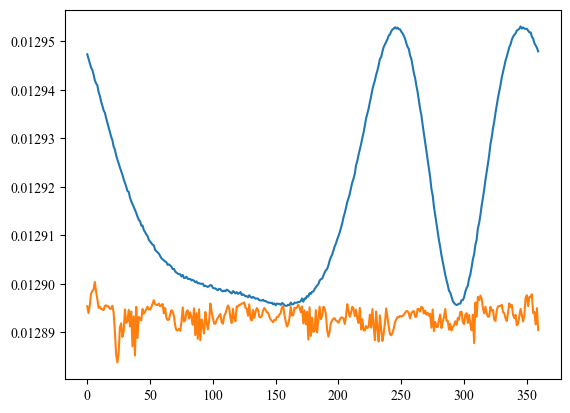

In [23]:
plt.plot(analytical_A_1d[9])
plt.plot(raptor_A_1d["analytical"][9])

In [24]:
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams[
    "text.latex.preamble"
] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
"""
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Times New Roman"  # 设置正常文本的字体
plt.rcParams["mathtext.it"] = "Times New Roman:italic"  # 设置斜体文本的字体
plt.rcParams["mathtext.bf"] = "Times New Roman:bold"  # 设置粗体文本的字体

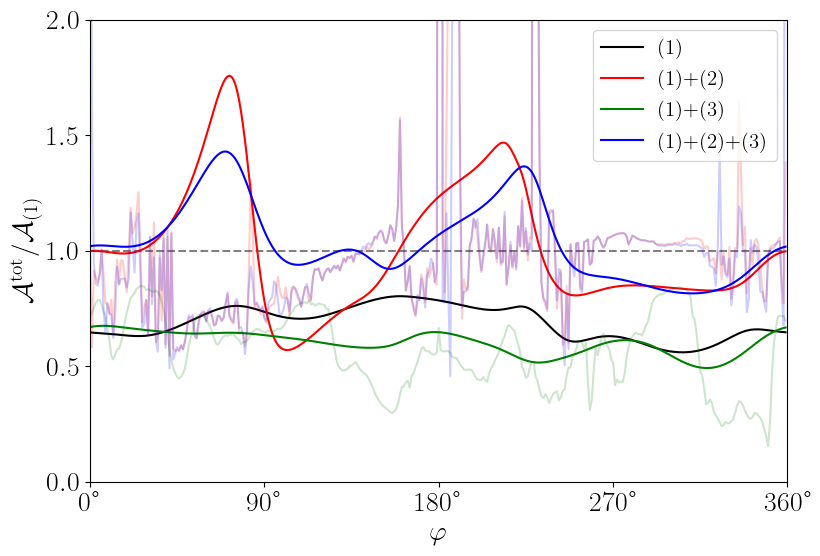

In [25]:
base_colors = plt.get_cmap("Set2").colors
from itertools import cycle, islice

colors = list(islice(cycle(base_colors), 10))
colors[1] = "red"
colors[3] = "green"
colors[0] = "blue"
colors[7] = "black"
# plt.plot(analytical_A_1d[4])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][4])
# 1. 将 y=1 的线设置为黑色
figure, ax = plt.subplots(figsize=(9, 6))
plt.plot([1] * 360, color="gray", linestyle="--")

# 2. 第一组数据: 不模糊的半透明，模糊的不透明，颜色相同
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][9]/analytical_A_1d[9], color=colors[0], alpha=0.2)
plt.plot(
    raptor_A_1d_blurred["data_in/grmhdData2110_400_eq_jonly.npy"][9]
    / analytical_A_1d[9],
    color=colors[7],
    alpha=1.0,
    label="(1)",
)

# 3. 第二组数据: 不模糊的半透明，模糊的不透明，颜色相同
plt.plot(
    raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][4] / analytical_A_1d[4],
    color=colors[1],
    alpha=0.2,
)
plt.plot(
    raptor_A_1d_blurred["data_in/grmhdData2110_400_eq_jonly.npy"][4]
    / analytical_A_1d[4],
    color=colors[1],
    alpha=1.0,
    label="(1)+(2)",
)

# 4. 第三组数据: 不模糊的半透明，模糊的不透明，颜色相同
plt.plot(
    raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][9] / analytical_A_1d[9],
    color=colors[3],
    alpha=0.2,
)
plt.plot(
    raptor_A_1d_blurred["data_in/grmhdData2110_400_jonly.npy"][9] / analytical_A_1d[9],
    color=colors[3],
    alpha=1.0,
    label="(1)+(3)",
)

plt.plot(
    raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][4] / analytical_A_1d[4],
    color=colors[0],
    alpha=0.2,
)
plt.plot(
    raptor_A_1d_blurred["data_in/grmhdData2110_400_jonly.npy"][4] / analytical_A_1d[4],
    color=colors[0],
    alpha=1.0,
    label="(1)+(2)+(3)",
)

ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos: f"{int(val)}°"))
plt.xlim(0, 360)
plt.xticks([0, 90, 180, 270, 360])
plt.xlabel(r"$\varphi$", fontsize=20)
plt.ylabel(r"$\mathcal{A}^{\mathrm{tot}}/\mathcal{A}_{(1)}$", fontsize=20)
plt.ylim(0, 2)
plt.yticks([0, 0.5, 1, 1.5, 2])
plt.legend(fontsize=15)
ax.tick_params(axis="both", labelsize=20)

(0.8, 1.2)

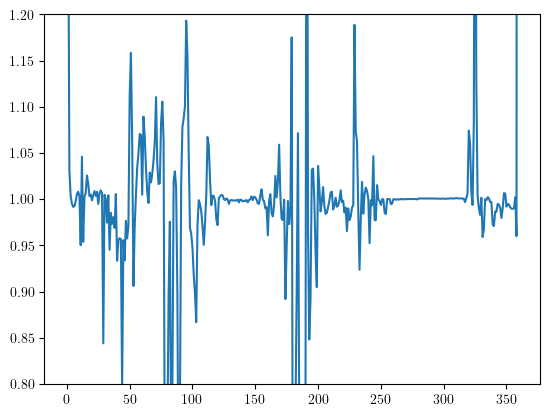

In [ ]:
plt.plot(
    raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][4]
    / raptor_A_1d["data_in/grmhdData2110_400_common.npy"][4]
)
plt.ylim(0.80, 1.2)
# plt.plot()

In [ ]:
raptor_A_1d_blurred.keys()

dict_keys(['data_in/grmhdData2110_400_common.npy', 'data_in/grmhdData2110_400_fake.npy', 'data_in/grmhdData2110_400_eq_jonly.npy', 'data_in/grmhdData2110_400_jonly.npy'])

(0.95, 1.05)

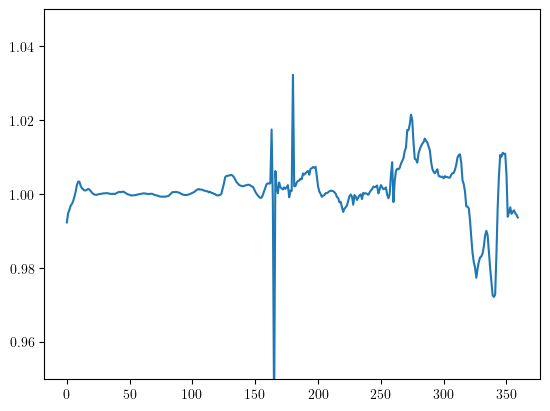

In [ ]:
plt.plot(
    raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][9]
    / raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9]
)
plt.ylim(0.95, 1.05)
# plt.plot()

In [26]:
grmhddata = np.load("data_in/grmhdData2110_400_common_noaxion.npy")
_grmhddata_jonly = np.load("data_in/grmhdData2110_400_jonly.npy")
_evpa = 0.5 * np.arctan2(_grmhddata_jonly[:, :, :, 2], _grmhddata_jonly[:, :, :, 1])
# _a=_fit_cos_evpa_A_only(_evpa)
# fig,ax=plot_quivers(grmhddata[0,:,:,0],(grmhddata[1,:,:,0]**2+grmhddata[1,:,:,1]**2)**0.5,_a)
# im=ax.imshow()
# fig.colorbar(im)
# ax.clim(0,25)

In [27]:
import matplotlib
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable

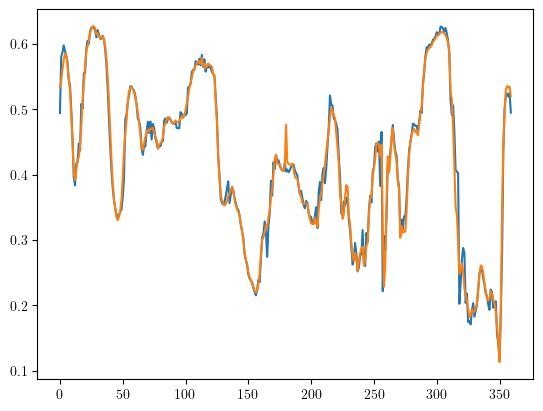

In [28]:
_x, _y = get_360_x_y(9).T
evpa_on_circle = _fit_cos_evpa_A_only(_evpa)[
    np.round(_x / 23.1131 * 200 + 199.5).astype(int),
    np.round(_y / 23.1131 * 200 + 199.5).astype(int),
]
plt.plot(evpa_on_circle / np.pi * 180)
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9] / np.pi * 180)

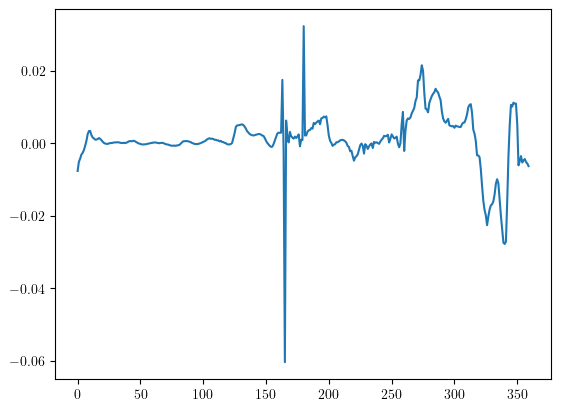

In [ ]:
plt.plot(
    (
        raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][9]
        - raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9]
    )
    / raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9]
)

In [34]:
1 + np.sqrt(1 - 0.9375**2)

np.float64(1.3479852726768764)

In [33]:
2 * (1 + np.cos(2 / 3 * np.arccos(-0.9375)))

np.float64(1.434516471960647)

In [ ]:
2 * (
    0.5
    + (1 - 0.9375**2 / 3) ** 0.5
    * np.cos(1 / 3 * np.arccos((1 - 0.9375**2) ** 0.5 / (1 - 0.9375**2 / 3) ** 0.5))
)

np.float64(2.560880271450589)

/tmp/ipykernel_271433/4092335044.py:140: RuntimeWarning: divide by zero encountered in log
  vx = (np.log(P / max_LP) + 4) * np.cos(_scaled_evpa) / 32
/tmp/ipykernel_271433/4092335044.py:141: RuntimeWarning: divide by zero encountered in log
  vy = (np.log(P / max_LP) + 4) * np.sin(_scaled_evpa) / 32
/tmp/ipykernel_271433/4092335044.py:141: RuntimeWarning: invalid value encountered in multiply
  vy = (np.log(P / max_LP) + 4) * np.sin(_scaled_evpa) / 32


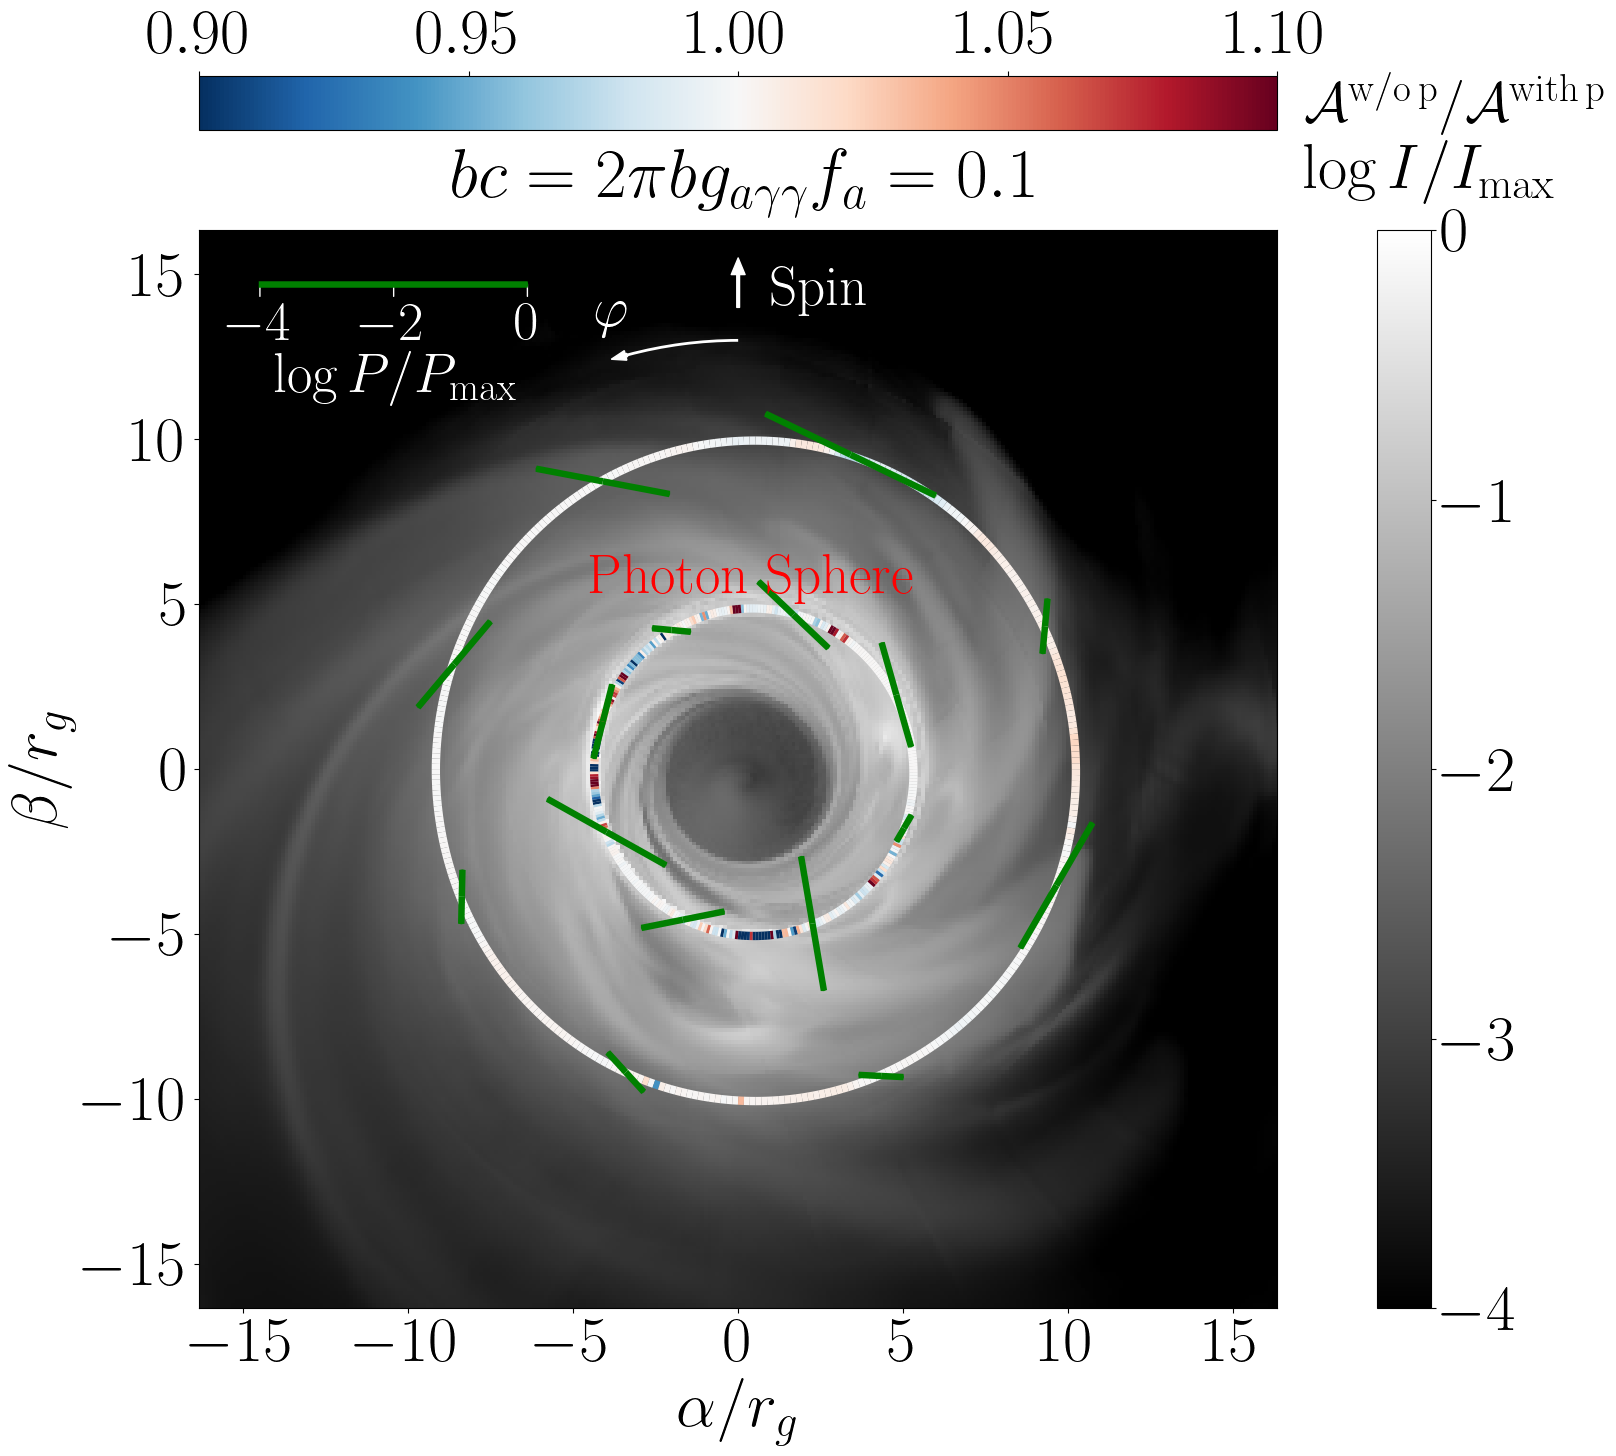

In [44]:
plt.close("all")
figure, ax = plt.subplots(figsize=(16, 16))
ax.tick_params(labelsize=46)
xgrid = deepcopy(_tmp_coords)
ygrid = deepcopy(_tmp_coords)
xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

bkg = ax.pcolormesh(
    xmesh,
    ymesh,
    np.log10(grmhddata[:, :, 0] / np.max(grmhddata[:, :, 0])),
    cmap="grey",
    vmin=-4,
    vmax=0,
    shading="auto",
)
ax.set_xlim(-16.3434, 16.3434)
ax.set_ylim(-16.3434, 16.3434)
ax.set_aspect("equal")
ax.set_xticks([-15, -10, -5, 0, 5, 10, 15])
ax.set_yticks([-15, -10, -5, 0, 5, 10, 15])
ax.set_xlabel(r"$\alpha/r_g$", fontsize=46)
ax.set_ylabel(r"$\beta/r_g$", fontsize=46)
# --- 从这里开始是修改的部分 ---
# 2. 从 ax 创建一个 divider
divider = make_axes_locatable(ax)
# 3. 在右侧创建一个新的坐标轴 cax，宽度是主图的 5%，间距是 0.3
cax = divider.append_axes("right", size="5%", pad=1.0)

# 4. 将 colorbar 画在新的 cax 上
clb = figure.colorbar(bkg, cax=cax)
clb.set_ticks([0, -1, -2, -3, -4])
# --- 修改结束 ---
# clb = figure.colorbar(bkg, ax=ax)
clb.ax.tick_params(labelsize=46)
clb.ax.set_title(r"$\log I/I_{\mathrm{max}}$", fontsize=46, pad=30, x=1)


col_indices = []
row_indices = []
colors = plt.get_cmap("tab10").colors
# _x,_y=get_360_x_y(1.4).T
# ax.plot(-np.append(_y,_y[0]),-np.append(_x,_x[0]))
_x, _y = get_360_x_y(9).T
# ax.plot(-np.append(_y,_y[0]),-np.append(_x,_x[0]),linestyle='--',linewidth=2,color=colors[0])
col_indices += list(np.round(_x / 23.1131 * 200 + 199.5).astype(int)[25::45])
row_indices += list(np.round(_y / 23.1131 * 200 + 199.5).astype(int)[25::45])

# evpa_on_circle = _fit_cos_evpa_A_only(_evpa)[
#     np.round(_x / 23.1131 * 200 + 199.5).astype(int),
#     np.round(_y / 23.1131 * 200 + 199.5).astype(int),
# ]
evpa_on_circle = (
    raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][9]
    - raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9]
) / raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9]
points = np.array([np.append(_x, _x[0]), np.append(_y, _y[0])]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
norm = Normalize(vmin=-0.1, vmax=0.1)
lc = LineCollection(segments, cmap=plt.get_cmap("RdBu_r"), norm=norm)
lc.set_array(evpa_on_circle)
lc.set_linewidth(6)
# lc.set_linestyle('--')
line = ax.add_collection(lc)
# cax_A = divider.append_axes("right", size="5%", pad=1.3)
# 如果你想用之前创建的 cax，可以这样：
# figure.colorbar(line, cax=cax, label='你的强度单位')
# 如果想新建一个 colorbar，可以这样：
# clb_A = figure.colorbar(line, cax=cax_A)
cax_A = divider.append_axes("top", size="5%", pad=1.0)  # 添加在底部
clb_A = figure.colorbar(line, cax=cax_A, orientation="horizontal")
clb_A.ax.xaxis.set_ticks_position("top")
clb_A.ax.xaxis.set_label_position("top")
clb_A.set_ticks(np.array([-0.1, -0.05, 0, 0.05, 0.1]))
clb_A.set_ticklabels([r"$0.90$", r"$0.95$", r"$1.00$", r"$1.05$", r"$1.10$"])
clb_A.ax.tick_params(labelsize=46)
# clb_A.ax.set_title(r"$\mathcal{A}^{\mathrm{tot}}$", fontsize=46, pad=30, x=1)
clb_A.ax.text(
    1.026,
    0.5,  # (x, y) in axes fraction coords
    r"$\mathcal{A}^{\mathrm{w/o\, p}}/\mathcal{A}^{\mathrm{with\, p}}$",
    fontsize=40,
    rotation=0,
    va="center",
    ha="left",
    transform=clb_A.ax.transAxes,
)

_x, _y = get_360_x_y(photon_sphere).T
# ax.plot(-np.append(_y,_y[0]),-np.append(_x,_x[0]),linestyle='--',linewidth=2,color=colors[1])
col_indices += list(np.round(_x / 23.1131 * 200 + 199.5).astype(int)[25::45])
row_indices += list(np.round(_y / 23.1131 * 200 + 199.5).astype(int)[25::45])

# --- 开始修改 ---
# evpa_on_circle = _fit_cos_evpa_A_only(_evpa)[
#     np.round(_x / 23.1131 * 200 + 199.5).astype(int),
#     np.round(_y / 23.1131 * 200 + 199.5).astype(int),
# ]
evpa_on_circle = (
    raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][4]
    - raptor_A_1d["data_in/grmhdData2110_400_common.npy"][4]
) / raptor_A_1d["data_in/grmhdData2110_400_common.npy"][4]
points = np.array([np.append(_x, _x[0]), np.append(_y, _y[0])]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lc = LineCollection(segments, cmap=plt.get_cmap("RdBu_r"), norm=norm)
lc.set_array(evpa_on_circle)
lc.set_linewidth(6)
# lc.set_linestyle('--')
line = ax.add_collection(lc)
# cax_A=divider.append_axes("right", size="5%", pad=1.5)
# 如果你想用之前创建的 cax，可以这样：
# figure.colorbar(line, cax=cax, label='你的强度单位')
# 如果想新建一个 colorbar，可以这样：
# clb_A=figure.colorbar(line, cax=cax_A)
# clb_A.ax.set_title("123")
# --- 修改结束 ---


# 2. 为 r=9 的圆添加标签
# ax.text(0.5, 10,
#         r'(1) $r=9r_g$',
#         color=colors[0],
#         fontsize=35,
#         horizontalalignment='center',
#         verticalalignment='bottom')
ax.text(
    0.46,
    5,
    r"Photon Sphere",
    color="red",
    fontsize=40,
    horizontalalignment="center",
    verticalalignment="bottom",
    zorder=30,
)

P = (_grmhddata_jonly[0, :, :, 1] ** 2 + _grmhddata_jonly[0, :, :, 2] ** 2) ** 0.5
_scaled_evpa = _scale_evpa(_evpa, 10)
max_LP = np.max(P)
vx = (np.log(P / max_LP) + 4) * np.cos(_scaled_evpa) / 32
vy = (np.log(P / max_LP) + 4) * np.sin(_scaled_evpa) / 32
mycmap = plt.get_cmap("gist_rainbow")
mynorm = matplotlib.colors.BoundaryNorm(range(0, 16, 1), ncolors=mycmap.N, clip=True)
# row_indices = [20, 60, 100, 140, 180, 220, 260, 300, 340, 380]
# col_indices = [20, 60, 100, 140, 180, 220, 260, 300, 340, 380]
quiver_color = "green"
for i in range(0, 1):
    q = ax.quiver(
        xmesh[col_indices, row_indices],
        ymesh[col_indices, row_indices],
        vx[i][col_indices, row_indices],
        vy[i][col_indices, row_indices],
        # i,
        headwidth=1,
        headlength=0.1,
        width=0.006,
        # cmap=mycmap,
        # norm=mynorm,
        color=quiver_color,
        units="width",
        scale=1,
        zorder=3,
    )
    # for i in range(9,17):
    ax.quiver(
        xmesh[col_indices, row_indices],
        ymesh[col_indices, row_indices],
        -vx[i][col_indices, row_indices],
        -vy[i][col_indices, row_indices],
        # i,
        headwidth=1,
        headlength=0.1,
        width=0.006,
        # cmap=mycmap,
        # norm=mynorm,
        color=quiver_color,
        units="width",
        scale=1,
        zorder=3,
    )
ax.quiverkey(
    q,
    X=0.18,  # 先放在正中间，确保能看见
    Y=0.95,  # 先放在正中间
    U=1 / 4,  # 你的箭头长度
    # label=r"$P = 1.00 P_{\mathrm{max}}$",
    label="",
    labelpos="S",
    coordinates="axes",
    # --- 强制指定一个鲜明的颜色 ---
    color=quiver_color,
    labelcolor=quiver_color,
    fontproperties={"size": 40},
)
arrow_length = 8.11
values = [1, 0.01, 0.0001]
values_text = [r"$0$", r"$-2$", r"$-4$"]

# 绘制代表 P_max 的主箭头
# ax.quiver(
#     0.34,0.95,
#     arrow_length,
#     0,
#     color="gold",
#     angles="xy",
#     scale_units="xy",
#     scale=1,
#     width=0.01,
#     headwidth=1,
#     headlength=0.1,
# )
ax.text(
    -10.4,
    11.0,
    r"$\log P/P_{\mathrm{max}}$",
    color="white",
    ha="center",
    va="bottom",
    fontsize=40,
)

# 在主箭头上添加标记
for value in values:
    position = (np.log10(value) + 4) / 4 * arrow_length + -14.50  # 计算标记位置
    # 使用 annotate 添加带引线的标签
    ax.annotate(
        values_text[values.index(value)],
        xy=(position, 14.9),  # 箭头指向的位置
        xytext=(position, 13.0),  # 文字标签的位置
        color="white",
        fontsize=40,
        ha="center",
        arrowprops=dict(arrowstyle="-", color="white", shrinkB=5),
    )

# 添加图表总标题
figure.suptitle(r"$bc=2\pi b g_{a\gamma\gamma}f_a=0.1$", fontsize=50, x=0.47, y=0.833)


ax.annotate(
    "",  # 不加文字，先画箭头
    xy=(0, 15.5),  # 箭头终点
    xytext=(0, 14),  # 箭头起点
    arrowprops=dict(facecolor="white", edgecolor="white", width=2, headwidth=10),
    zorder=50,
)
ax.text(
    1,
    14.5,
    r"Spin",
    color="white",
    fontsize=40,
    ha="left",
    va="center",
)

from matplotlib.patches import Arc, FancyArrow

arc_R = 26

theta2 = 105  # 终点角度
arc = Arc(
    (0, 0),  # 圆心在 (0,0)，也就是黑洞中心
    width=arc_R,
    height=arc_R,  # 圆弧大小
    theta1=90,
    theta2=theta2,  # 从 0° 到 40° 的弧度
    color="white",
    lw=2,
)
ax.add_patch(arc)

# 在弧的终点加一个箭头
end_x = arc_R * np.cos(np.deg2rad(theta2)) / 2
end_y = arc_R * np.sin(np.deg2rad(theta2)) / 2
arrow = FancyArrow(
    end_x,
    end_y,
    -0.5 * np.sin(np.deg2rad(theta2)),  # dx 沿切线方向
    0.5 * np.cos(np.deg2rad(theta2)),  # dy 沿切线方向
    width=0.1,
    color="white",
    length_includes_head=True,
)
ax.add_patch(arrow)

# 添加 φ 标签
ax.text(
    -3.8,
    13.8,  # 标签位置
    r"$\varphi$",
    color="white",
    fontsize=40,
    ha="center",
    va="center",
)


plt.show()

In [42]:
raise KeyboardInterrupt

KeyboardInterrupt: 

In [ ]:
# raptor_A_1d={}
r_coord = np.load("data_in/r_coord_400.npy")
for grmhd_data_path in ["data_in/grmhdData2110_400_common.npy"]:
    grmhddata = np.load(grmhd_data_path)
    # raptor_A_1d[grmhd_data_path]={}
    for w in [9]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _aaa, _bbb, _tmp_evpa_1d, _ = get_raptor_evpa(
            grmhddata,
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=0,
            oneD_coord=None,
            rotation_angle=45 / 180 * np.pi,
            final_shape=400,
            final_fov=46.2262,
        )
        # raptor_A_1d[grmhd_data_path][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0


In [ ]:
# raptor_A_1d={}
r_coord = np.load("data_in/r_coord_400.npy")
for grmhd_data_path in ["data_in/grmhdData2110_400_common.npy"]:
    grmhddata = np.load(grmhd_data_path)
    # raptor_A_1d[grmhd_data_path]={}
    for w in [9]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _aaa, _bbb, _tmp_evpa_1d, _ = get_raptor_evpa(
            grmhddata,
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=0,
            oneD_coord=get_360_x_y(9),
            oneDmethod=1,
            rotation_angle=45 / 180 * np.pi,
            final_shape=400,
            final_fov=46.2262,
        )
        # raptor_A_1d[grmhd_data_path][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0


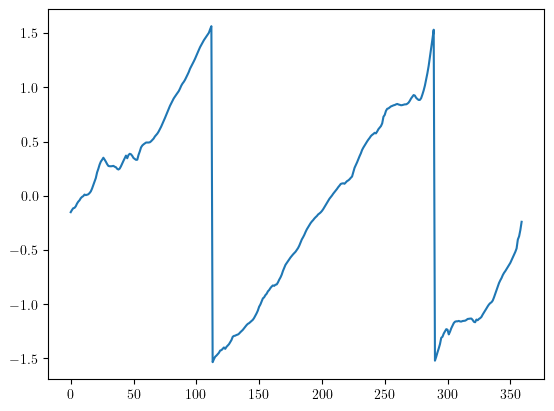

In [ ]:
plt.plot(_tmp_evpa_1d[0, 0])
# plt.plot(_evpa[0][np.round(_x/23.1131*200+199.5).astype(int),np.round(_y/23.1131*200+199.5).astype(int)])

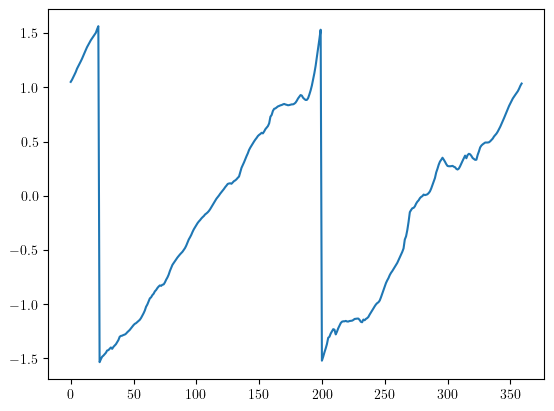

In [ ]:
plt.plot(np.roll(_tmp_evpa_1d[0, 0], -90))
# plt.plot(_evpa[0][np.round(_x/23.1131*200+199.5).astype(int),np.round(_y/23.1131*200+199.5).astype(int)])

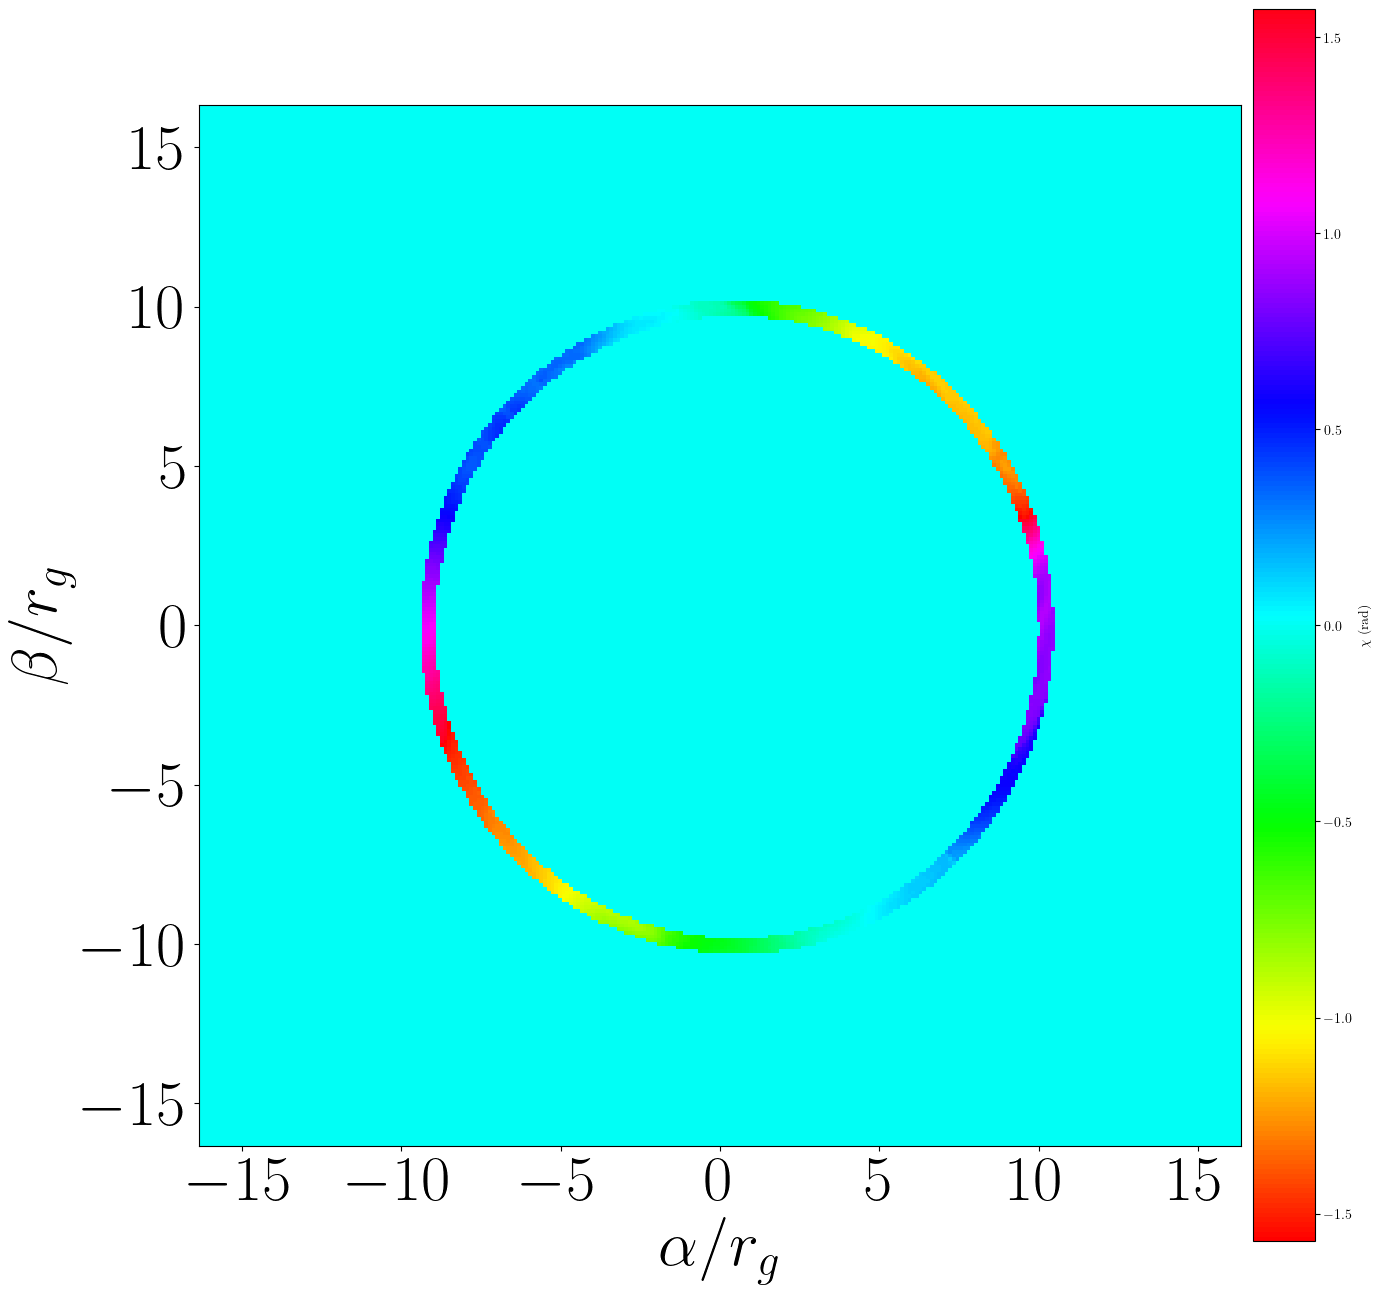

In [ ]:
plt.close("all")
figure, ax = plt.subplots(figsize=(16, 16))
ax.tick_params(labelsize=46)
xgrid = deepcopy(_tmp_coords)
ygrid = deepcopy(_tmp_coords)
xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

bkg = ax.pcolormesh(
    xmesh,
    ymesh,
    _bbb[0, 0] * r_s_coords,
    cmap="hsv",
    vmin=-np.pi / 2,
    vmax=np.pi / 2,
    shading="auto",
)
plt.colorbar(bkg, ax=ax, label=r"$\chi$ (rad)", pad=0.01)
ax.set_xlim(-16.3434, 16.3434)
ax.set_ylim(-16.3434, 16.3434)
ax.set_aspect("equal")
ax.set_xticks([-15, -10, -5, 0, 5, 10, 15])
ax.set_yticks([-15, -10, -5, 0, 5, 10, 15])
ax.set_xlabel(r"$\alpha/r_g$", fontsize=46)
ax.set_ylabel(r"$\beta/r_g$", fontsize=46)
_x, _y = get_360_x_y(9).T
# ax.plot(np.append(_x,_x[0]),np.append(_y,_y[0]),linestyle='--',linewidth=2,color="white")
# ax.plot(-np.append(_y,_y[0]),-np.append(_x,_x[0]),linestyle='--',linewidth=2,color="white")

In [ ]:
_aaa[0, 0, :, :, 0]

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

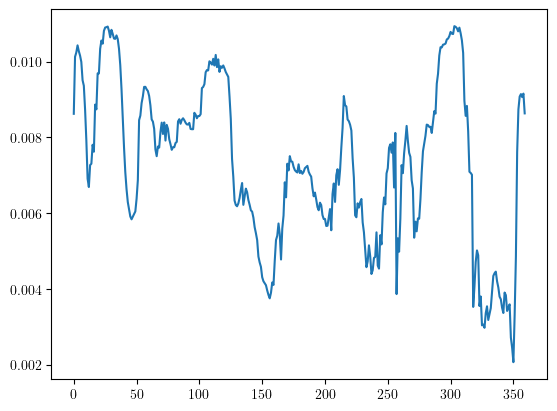

In [ ]:
_x, _y = get_360_x_y(9).T

evpa_on_circle = _fit_cos_evpa_A_only(_evpa)[
    np.round(_x / 23.1131 * 200 + 199.5).astype(int),
    np.round(_y / 23.1131 * 200 + 199.5).astype(int),
]
plt.plot(evpa_on_circle)

In [ ]:
raptor_A_1d = {}
r_coord = np.load("data_in/r_coord_400.npy")
for grmhd_data_path in ["data_in/grmhdData2110_400_common.npy"]:
    grmhddata = np.load(grmhd_data_path)
    raptor_A_1d[grmhd_data_path] = {}
    for w in [9]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _, _, _tmp_evpa_1d, _ = get_raptor_evpa(
            grmhddata,
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=0,
            oneD_coord=get_360_x_y(w),
            oneDmethod=1,
            rotation_angle=0,
        )
        raptor_A_1d[grmhd_data_path][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

    # _,_,_tmp_evpa_1d,_=get_raptor_evpa(grmhddata,phi_average=False)
    # raptor_A_1d[grmhd_data_path][0]=_fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0


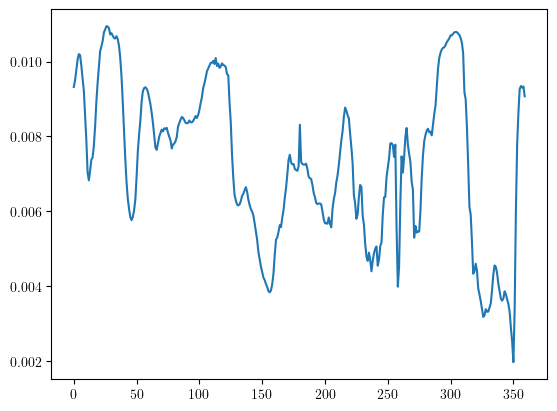

In [ ]:
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9])

In [ ]:
plt.cla()
plt.clf()
plt.imshow(_a, extent=[-fov / 2, fov / 2, -fov / 2, fov / 2])
_x, _y = get_360_x_y(photon_sphere).T
plt.plot(-np.append(_y, _y[0]), -np.append(_x, _x[0]))
_x, _y = get_360_x_y(9).T
plt.plot(-np.append(_y, _y[0]), -np.append(_x, _x[0]))
# plt.plot(np.append(_x,_x[0]),np.append(_y,_y[0]),color='white')
plt.colorbar()
plt.clim(0, 0.02)

NameError: name '_a' is not defined

<Figure size 640x480 with 0 Axes>

In [ ]:
_a

array([[4.90653893e-18, 3.50542935e-16, 3.38886567e-16, ...,
        7.35980840e-18, 0.00000000e+00, 9.81307787e-18],
       [1.85217783e-16, 3.64413753e-16, 9.57973456e-16, ...,
        7.35980840e-18, 0.00000000e+00, 4.90653893e-18],
       [2.30864910e-16, 2.26432918e-16, 1.44373397e-16, ...,
        2.45326947e-18, 9.81307787e-18, 0.00000000e+00],
       ...,
       [1.65964795e-14, 7.61329917e-15, 1.42789978e-15, ...,
        1.83995210e-18, 1.83995210e-18, 1.22663473e-18],
       [4.47498139e-16, 5.29826695e-16, 5.16204857e-16, ...,
        0.00000000e+00, 3.06658683e-19, 6.13317367e-19],
       [2.94790723e-16, 1.48072647e-16, 2.69901455e-16, ...,
        7.66646708e-20, 7.66646708e-20, 0.00000000e+00]])

In [ ]:
grmhddata = np.load("data_in/grmhdData2110_400_fake.npy")
_evpa = 0.5 * np.arctan2(grmhddata[:, :, :, 1], grmhddata[:, :, :, 2])
_a = _fit_cos_evpa_A_only(_evpa)

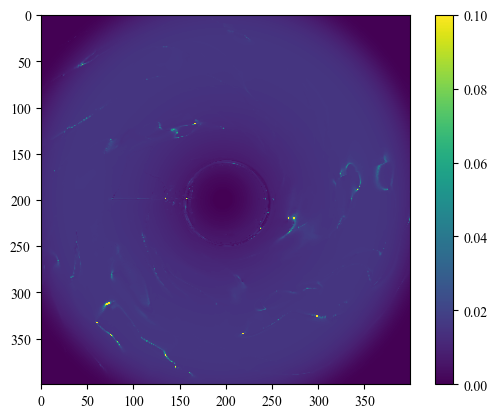

In [ ]:
plt.cla()
plt.clf()
grmhdData1600 = np.load("data_in/grmhdData2110_400_fake.npy", allow_pickle=True)
plt.imshow(
    _fit_cos_evpa_A_only(
        0.5 * np.arctan2(grmhdData1600[:, :, :, 1], grmhdData1600[:, :, :, 2])
    )
)
plt.colorbar()
plt.clim(0, 0.1)
plt.show()

(0.0, 0.02)

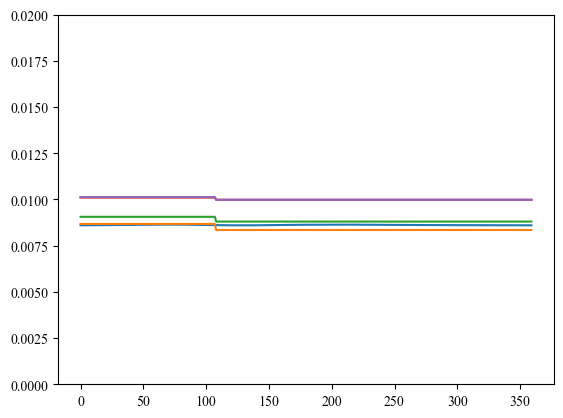

In [ ]:
plt.plot(analytical_A_1d[5])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][5])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][5])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][5])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][5])
plt.ylim(0, 0.02)

(0.0, 0.02)

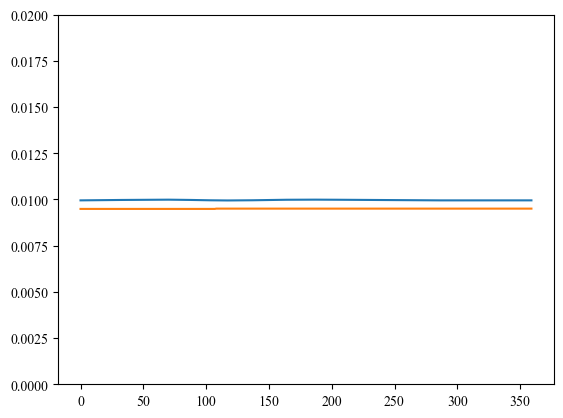

In [ ]:
plt.plot(analytical_A_1d[6])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][6])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][6])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][6])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][6])
plt.ylim(0, 0.02)

(0.0, 0.02)

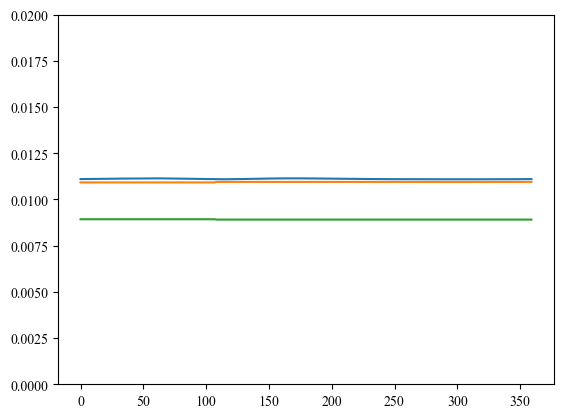

In [ ]:
plt.plot(analytical_A_1d[7])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][7])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][7])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][7])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][7])
plt.ylim(0, 0.02)

(0.0, 0.02)

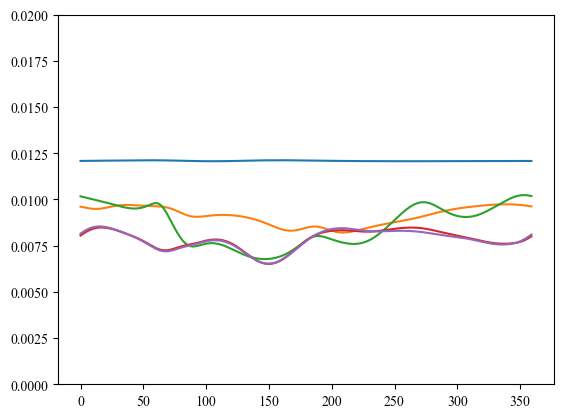

In [ ]:
plt.plot(analytical_A_1d[8])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][8])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][8])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][8])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][8])
plt.ylim(0, 0.02)

(0.0, 0.02)

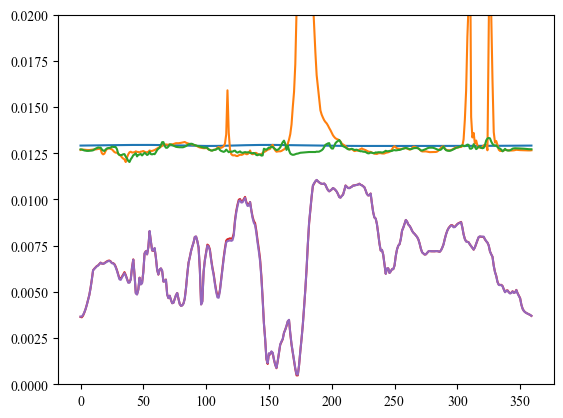

In [ ]:
plt.plot(analytical_A_1d[9])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][9])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][9])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][9])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9])
plt.ylim(0, 0.02)

(0.0, 0.02)

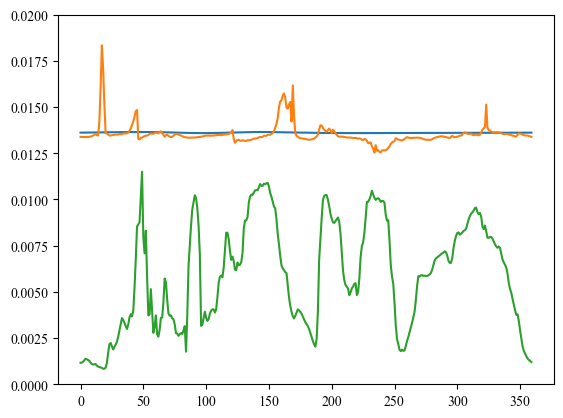

In [ ]:
plt.plot(analytical_A_1d[10])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][10])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][10])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][10])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][10])
plt.ylim(0, 0.02)

In [ ]:
raptor_A_1d = {}
r_coord = np.load("data_in/r_coord_400.npy")
for grmhd_data_path in grmhd_data_paths:
    grmhddata = np.load(grmhd_data_path)
    raptor_A_1d[grmhd_data_path] = {}
    for w in [4, 5, 6, 7, 8, 9, 10]:
        r_s_coords = deepcopy(r_coord)
        r_s_coords[np.isnan(r_s_coords)] = 0
        r_s_coords[r_s_coords > w + r_width / 2] = 0
        r_s_coords[r_s_coords < w - r_width / 2] = 0
        r_s_coords[r_s_coords != 0] = 1
        _, _, _tmp_evpa_1d, _ = get_raptor_evpa(
            grmhddata,
            image_mask=r_s_coords,
            # phi_average=False,
            gaussian_kernel=0,
            oneD_coord=get_360_x_y(w),
        )
        raptor_A_1d[grmhd_data_path][w] = _fit_cos_evpa_A_only(_tmp_evpa_1d[0])

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


(0.0, 0.02)

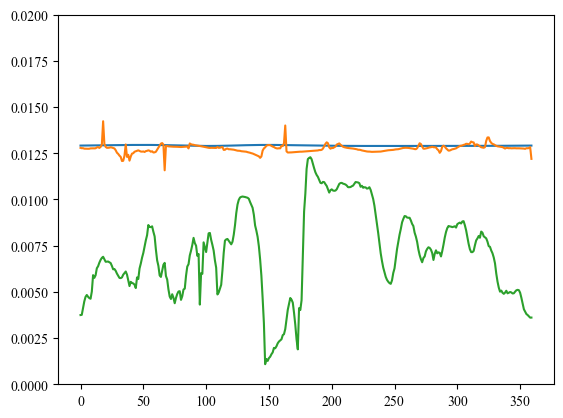

In [ ]:
plt.plot(analytical_A_1d[9])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_fake.npy"][10])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_eq_jonly.npy"][9])
# plt.plot(raptor_A_1d["data_in/grmhdData2110_400_jonly.npy"][10])
plt.plot(raptor_A_1d["data_in/grmhdData2110_400_common.npy"][9])
plt.ylim(0, 0.02)

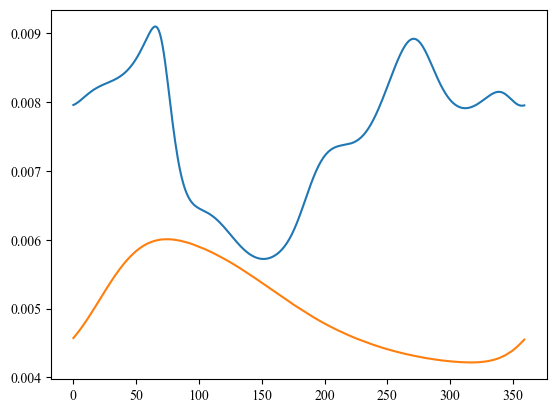

In [ ]:
plt.plot(raptor_A_1d["data/grmhdData2110_400_common.npy"][4])
plt.plot(analytical_A_1d[4])

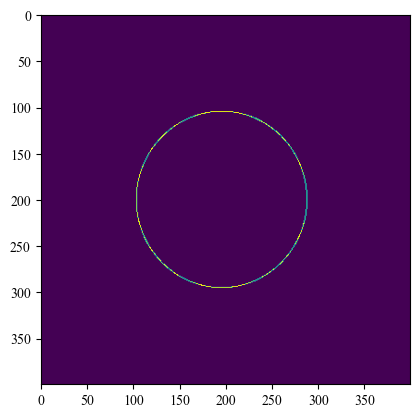

In [ ]:
r_coord = np.load("data_in/r_coord_400.npy")
r_s_coords = deepcopy(r_coord)
r_s_coords[np.isnan(r_s_coords)] = 0
r_s_coords[r_s_coords > 10 + 0.12 / 2] = 0
r_s_coords[r_s_coords < 10 - 0.12 / 2] = 0
r_s_coords[r_s_coords != 0] = 1
plt.imshow(r_s_coords)

In [ ]:
grmhdData_fake = np.load("data_in/grmhdData2110_400_fake.npy", allow_pickle=True)

In [ ]:
_, EVPA, _, EVPA_1d = get_raptor_evpa(
    grmhdData_fake, image_mask=r_s_coords, init_fov=46.2262
)

0


In [ ]:
from scipy.interpolate import RegularGridInterpolator

resolution = 64
_tmp_coords = (
    np.linspace(-(resolution - 1) / 2, (resolution - 1) / 2, resolution)
    * 32.6868
    / resolution
)

interp = RegularGridInterpolator((_tmp_coords, _tmp_coords), EVPA[0][0])

In [ ]:
np.stack(
    [
        np.cos(np.linspace(0, 2 * np.pi, 360, endpoint=False)),
        np.sin(np.linspace(0, 2 * np.pi, 360, endpoint=False)),
    ],
    axis=1,
)[:, 0]

array([ 1.00000000e+00,  9.99847695e-01,  9.99390827e-01,  9.98629535e-01,
        9.97564050e-01,  9.96194698e-01,  9.94521895e-01,  9.92546152e-01,
        9.90268069e-01,  9.87688341e-01,  9.84807753e-01,  9.81627183e-01,
        9.78147601e-01,  9.74370065e-01,  9.70295726e-01,  9.65925826e-01,
        9.61261696e-01,  9.56304756e-01,  9.51056516e-01,  9.45518576e-01,
        9.39692621e-01,  9.33580426e-01,  9.27183855e-01,  9.20504853e-01,
        9.13545458e-01,  9.06307787e-01,  8.98794046e-01,  8.91006524e-01,
        8.82947593e-01,  8.74619707e-01,  8.66025404e-01,  8.57167301e-01,
        8.48048096e-01,  8.38670568e-01,  8.29037573e-01,  8.19152044e-01,
        8.09016994e-01,  7.98635510e-01,  7.88010754e-01,  7.77145961e-01,
        7.66044443e-01,  7.54709580e-01,  7.43144825e-01,  7.31353702e-01,
        7.19339800e-01,  7.07106781e-01,  6.94658370e-01,  6.81998360e-01,
        6.69130606e-01,  6.56059029e-01,  6.42787610e-01,  6.29320391e-01,
        6.15661475e-01,  

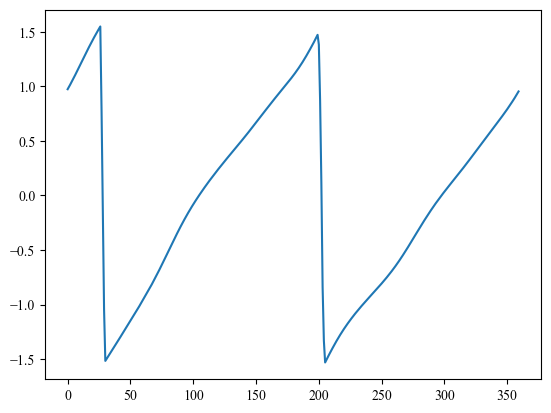

In [ ]:
plt.plot(
    interp(
        10
        * np.stack(
            [
                np.cos(np.linspace(0, 2 * np.pi, 360, endpoint=False)),
                np.sin(np.linspace(0, 2 * np.pi, 360, endpoint=False)),
            ],
            axis=1,
        )
    )
)

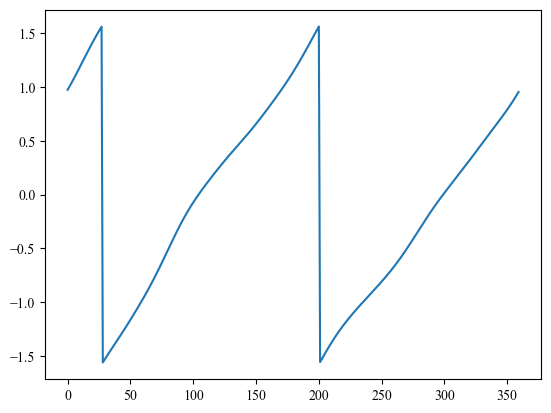

In [ ]:
plt.plot(EVPA_1d[0][0])

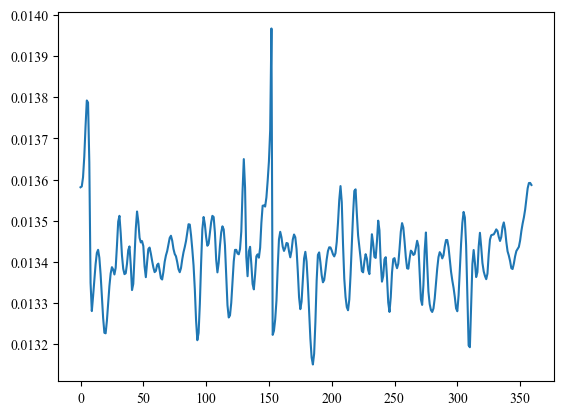

In [ ]:
plt.plot(_fit_cos_evpa_A_only(a_evpa[10][0]))

In [ ]:
plt.plot()

0
0
0
0
0
0


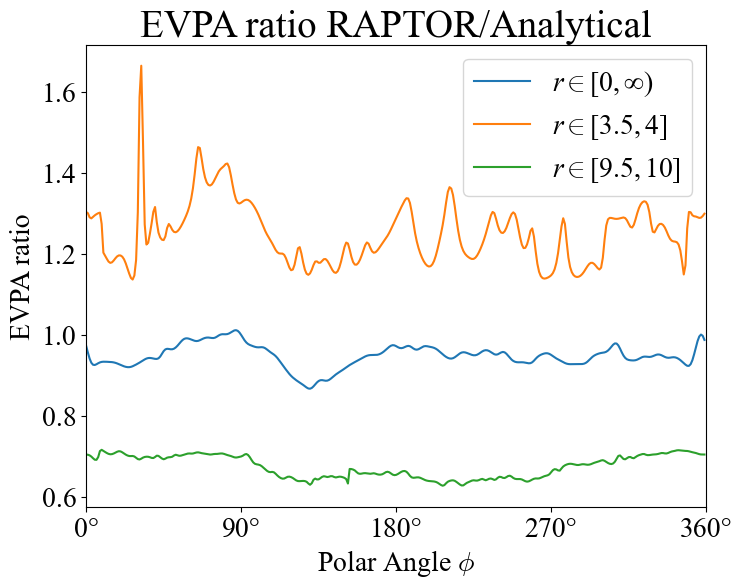

In [ ]:
grmhdData1600_fake = np.load("data_in/grmhdData1600fake.npy", allow_pickle=True)
axion_field_coord = np.load("data_in/axion_field_coord_16.npy")
r_coord = np.load("data_in/r_coord.npy")
fig, a_evpa = plot_evpa_r_and_a(grmhdData1600_fake, axion_field_coord, r_coord)
fig.savefig("../Plot/images/Axion Signal/evpa_ratio_fake.png")
fig.show()

0
0
0
0
0
0


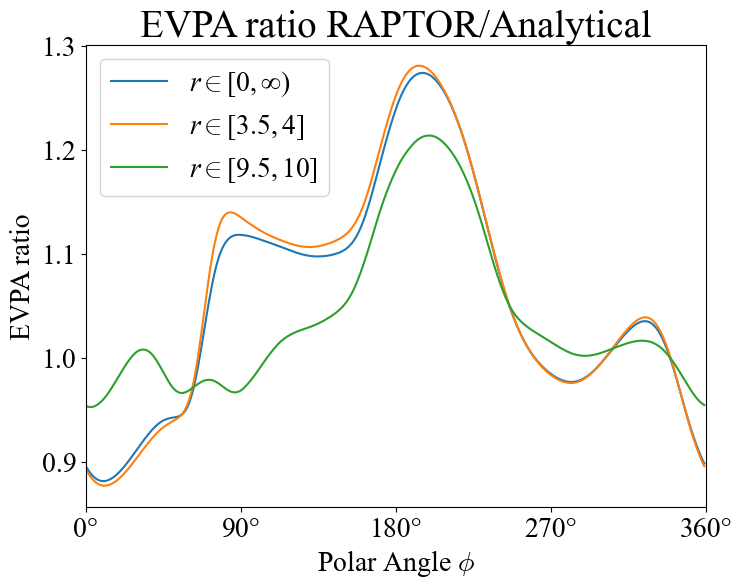

In [ ]:
grmhdData1600_eq_jonly = np.load(
    "data_in/grmhdData1600_eq_jonly.npy", allow_pickle=True
)
axion_field_coord = np.load("data_in/axion_field_coord_16.npy")
r_coord = np.load("data_in/r_coord.npy")
fig = plot_evpa_r_and_a(grmhdData1600_eq_jonly, axion_field_coord, r_coord)
fig.savefig("../Plot/images/Axion Signal/evpa_ratio_eq_jonly.png")
fig.show()

0
0
0
0
0
0


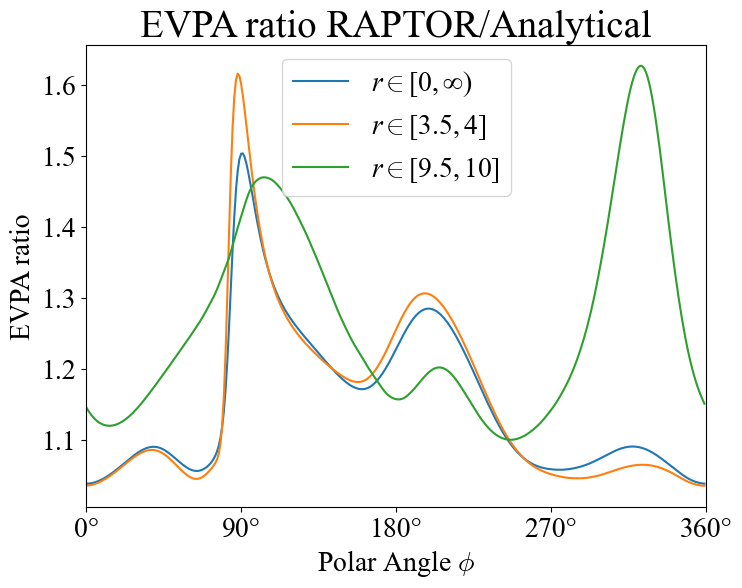

In [ ]:
grmhdData1600_jonly = np.load("data_in/grmhdData1600_jonly.npy", allow_pickle=True)
axion_field_coord = np.load("data_in/axion_field_coord_16.npy")
r_coord = np.load("data_in/r_coord.npy")
fig = plot_evpa_r_and_a(grmhdData1600_jonly, axion_field_coord, r_coord)
fig.savefig("../Plot/images/Axion Signal/evpa_ratio_jonly.png")
fig.show()

0
0
0
0
0
0


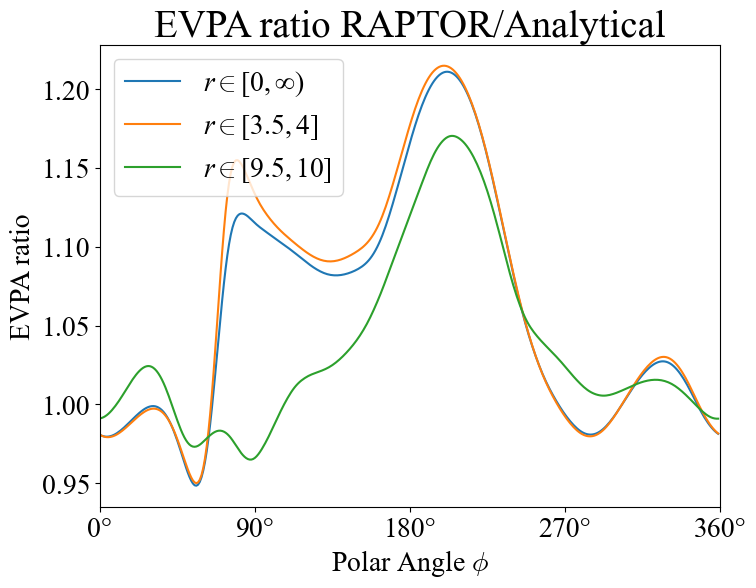

In [ ]:
grmhdData1600 = np.load("data_in/grmhdData1600.npy", allow_pickle=True)
axion_field_coord = np.load("data_in/axion_field_coord_16.npy")
r_coord = np.load("data_in/r_coord.npy")
fig = plot_evpa_r_and_a(grmhdData1600, axion_field_coord, r_coord)
fig.savefig("../Plot/images/Axion Signal/evpa_ratio_common.png")
fig.show()

In [ ]:
grmhdData1600 = np.load("data_in/grmhdData1600fake.npy", allow_pickle=True)
# grmhdData1600_fake[:,50:100,50:100,1:3]=grmhdData1600_fake[:,20:70,50:100,1:3]
axion_field_coord = np.load("data_in/axion_field_coord_16.npy")
r_s_coords = np.load("data_in/r_coord.npy")
r_s_coords[np.isnan(r_s_coords)] = 0
# r_s_coords[r_s_coords>10]=0
# r_s_coords[r_s_coords<9.5]=0
r_s_coords[r_s_coords != 0] = 1
_grmhddata = deepcopy(grmhdData1600)
_grmhddata[:, :, :, 0] *= r_s_coords
_1, _2, _3, _4 = getGRMHDDataAfterImageS(
    _grmhddata[np.newaxis, ...], init_fov=46.2262, gaussian_kernel=0, rotation_angle=0
)

0


In [ ]:
grmhdData1600 = np.load("data_in/grmhdData2110_400_fake.npy", allow_pickle=True)
plt.imshow(
    _fit_cos_evpa_A_only(
        0.5 * np.arctan2(grmhdData1600[:, :, :, 1], grmhdData1600[:, :, :, 2])
    )
)
plt.colorbar()
plt.clim(0, 0.1)

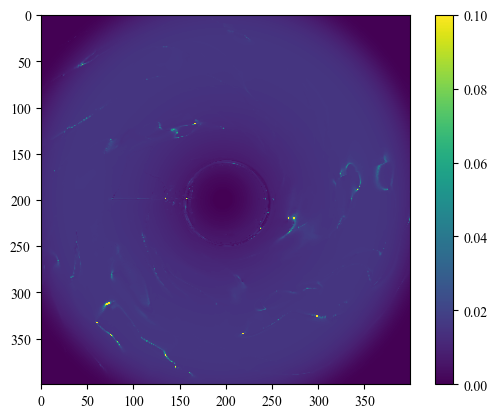

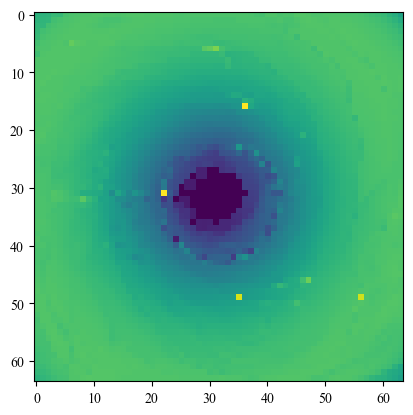

In [ ]:
plt.imshow(_fit_cos_evpa_A_only(_2[0]))

In [ ]:
np.logspace(np.log10(0.5), np.log10(2.0), 500)[250]

np.float64(1.0013900377142089)

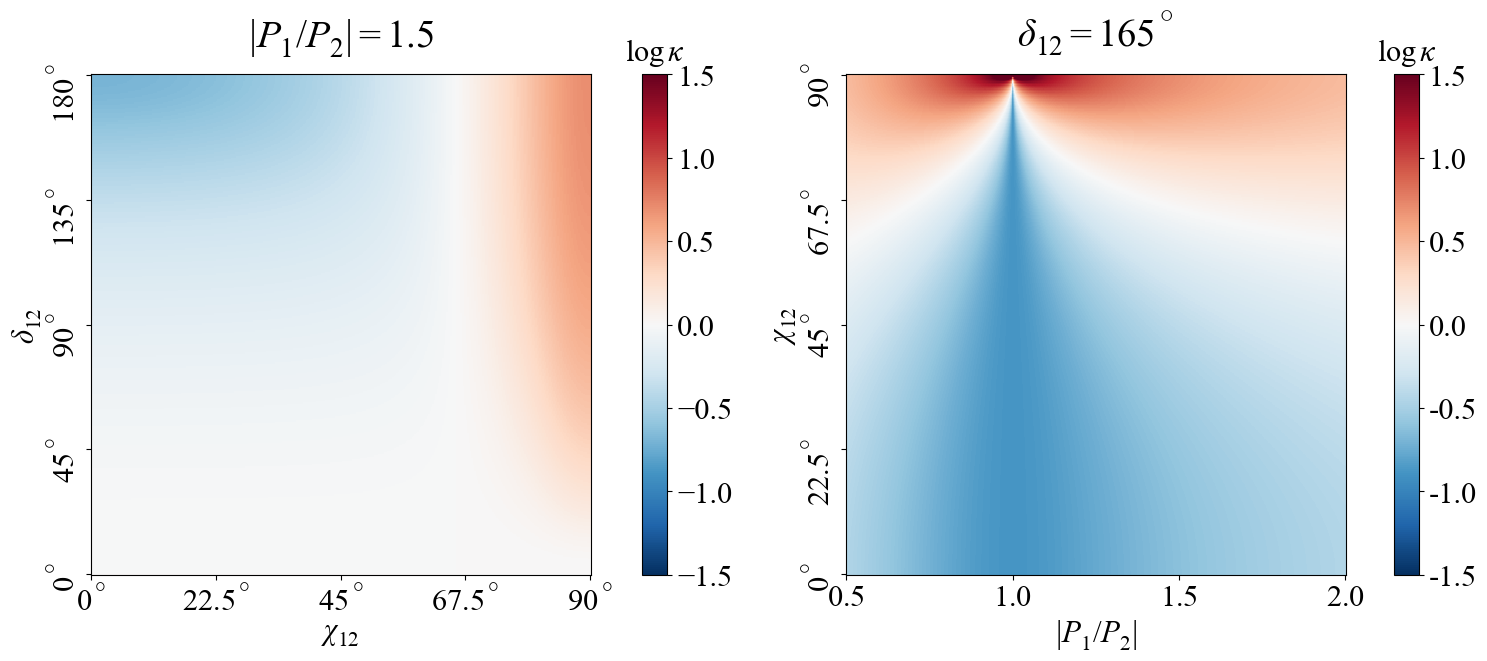

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import io

from PIL import Image


def kappa(delta_12, delta_chi_12, P1, P2):
    P1_plus_P2 = np.sqrt(P1**2 + P2**2 + 2 * P1 * P2 * np.cos(2 * delta_chi_12))
    frac = (P1**2 - P2**2) / P1_plus_P2**2
    return np.sqrt(np.cos(delta_12 / 2) ** 2 + np.sin(delta_12 / 2) ** 2 * frac**2)


def plot_kappa(fontsize=12):

    fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(15, 6.5))

    shrink = 1

    # -------- 图2左 --------
    delta_12 = np.linspace(0, np.pi, 360)
    delta_chi_12 = np.linspace(0, np.pi / 2, 360)
    X_left, Y_left = np.meshgrid(delta_chi_12, delta_12)
    Z_left = kappa(Y_left, X_left, 1.5, 1.0)

    im1 = ax1.pcolormesh(
        delta_chi_12, delta_12, np.log10(Z_left), shading="auto", cmap="RdBu_r"
    )
    ax1.set_xlabel(r"$\chi_{12}$", fontsize=fontsize)
    ax1.set_ylabel(r"$\delta_{12}$", fontsize=fontsize)
    ax1.tick_params(labelsize=fontsize)
    ax1.set_xticks([0, np.pi / 8, np.pi / 4, np.pi / 8 * 3, np.pi / 2])
    ax1.set_xticklabels(
        [r"$0^\circ$", r"$22.5^\circ$", r"$45^\circ$", r"$67.5^\circ$", r"$90^\circ$"],
        fontsize=fontsize,
    )
    ax1.set_yticks([0, np.pi / 4, np.pi / 2, np.pi / 4 * 3, np.pi])
    ax1.set_yticklabels(
        [r"$0^\circ$", r"$45^\circ$", r"$90^\circ$", r"$135^\circ$", r"$180^\circ$"],
        fontsize=fontsize,
        rotation=90,
    )
    ax1.set_aspect(0.5, adjustable="box")
    cbar = fig.colorbar(im1, ax=ax1, shrink=shrink)
    cbar.ax.set_title(r"$\log{\kappa}$", fontsize=fontsize, pad=10)  # 把 label 放到顶部
    cbar.ax.tick_params(labelsize=fontsize)
    im1.set_clim(-1.5, 1.5)

    ax1.set_title(r"$\left|P_1/P_2\right|=1.5$", fontsize=fontsize + 6, pad=20)
    # plt.tight_layout()
    # plt.savefig("../Plot/images/Amplitude Combination/_tmp_left.png")
    # plt.show()

    # -------- 图2右 --------
    ratio = np.linspace(0.5, 2.0, 500)
    delta_chi_12 = np.linspace(0, np.pi / 2, 360)
    X_right, Y_right = np.meshgrid(ratio, delta_chi_12)
    P2 = 1.0
    P1 = P2 * ratio
    Z_right = kappa(165 / 180 * np.pi, Y_right, P1, P2)

    im2 = ax2.pcolormesh(
        ratio, delta_chi_12, np.log10(Z_right), shading="auto", cmap="RdBu_r"
    )
    ax2.set_xlabel(r"$\left|P_1/P_2\right|$", fontsize=fontsize)
    ax2.set_ylabel(r"$\chi_{12}$", fontsize=fontsize)
    ax2.tick_params(labelsize=fontsize)
    ax2.set_xticks([0.5, 1.0, 1.5, 2.0])
    ax2.set_xticklabels([r"$0.5$", r"$1.0$", r"$1.5$", r"$2.0$"], fontsize=fontsize)
    ax2.set_yticks([0, np.pi / 8, np.pi / 4, np.pi / 8 * 3, np.pi / 2])
    ax2.set_yticklabels(
        [r"$0^\circ$", r"$22.5^\circ$", r"$45^\circ$", r"$67.5^\circ$", r"$90^\circ$"],
        fontsize=fontsize,
        rotation=90,
    )
    ax2.set_aspect(3 / np.pi, adjustable="box")
    cbar = plt.colorbar(im2, format="%.1f", ax=ax2, shrink=shrink)
    cbar.ax.set_title(r"$\log{\kappa}$", fontsize=fontsize, pad=10)  # 顶端显示
    cbar.ax.tick_params(labelsize=fontsize)
    ax2.set_title(r"$\delta_{12}=165^\circ$", fontsize=fontsize + 6, pad=20)
    im2.set_clim(-1.5, 1.5)
    # plt.tight_layout()
    # plt.savefig("../Plot/images/Amplitude Combination/_tmp_right.png")
    # # 保存 ax1
    # extent = ax1.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    # fig.savefig("../Plot/images/Amplitude Combination/_tmp_left.png", bbox_inches=extent)

    # # 保存 ax2
    # extent = ax2.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    # fig.savefig("../Plot/images/Amplitude Combination/_tmp_right.png", bbox_inches=extent)
    return fig


# 调用函数，调节字体大小
fig = plot_kappa(fontsize=22)
# fig.savefig("../Plot/images/Amplitude Combination/total.png")

In [ ]:
from PIL import Image

# 打开已经保存的总图
img = Image.open("../Plot/images/Amplitude Combination/total.png")  # 替换成你的文件路径
w, h = img.size

# 左半部分
left_img = img.crop((0, 0, w // 2, h))
left_img.save("../Plot/images/Amplitude Combination/_tmp_left.png")

# 右半部分
right_img = img.crop((w // 2, 0, w, h))
right_img.save("../Plot/images/Amplitude Combination/_tmp_right.png")

In [ ]:
import h5py
import numpy as np

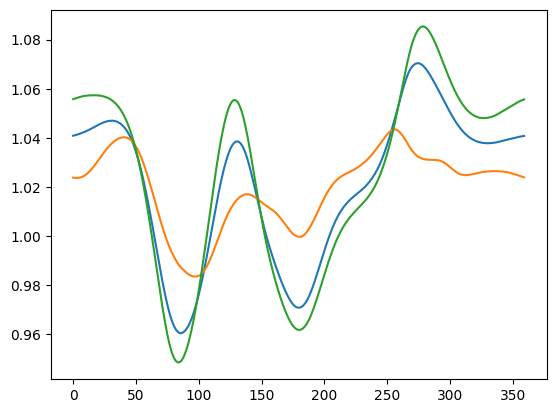

In [ ]:
plt.plot(
    _fit_cos_evpa_A_only(fake_a_evpa[0][0]) / _fit_cos_evpa_A_only(fake_r_evpa[0][0])
)
plt.plot(
    _fit_cos_evpa_A_only(fake_a_evpa[10][0]) / _fit_cos_evpa_A_only(fake_r_evpa[10][0])
)
plt.plot(
    _fit_cos_evpa_A_only(fake_a_evpa[4][0]) / _fit_cos_evpa_A_only(fake_r_evpa[4][0])
)
# plt.ylim(0.9,1.1)

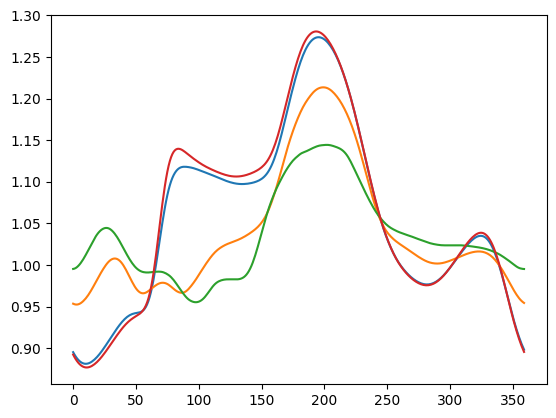

In [ ]:
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa[0][0])
    / _fit_cos_evpa_A_only(eq_jonly_r_evpa[0][0])
)
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa[10][0])
    / _fit_cos_evpa_A_only(eq_jonly_r_evpa[10][0])
)
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa[14][0])
    / _fit_cos_evpa_A_only(eq_jonly_r_evpa[14][0])
)
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa[4][0])
    / _fit_cos_evpa_A_only(eq_jonly_r_evpa[4][0])
)
# plt.ylim(0.9,1.1)

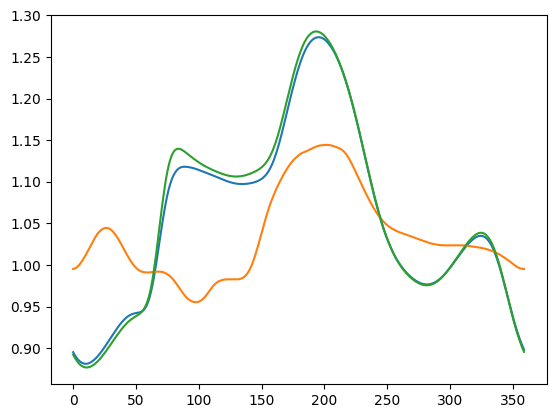

In [ ]:
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa[0]) / _fit_cos_evpa_A_only(eq_jonly_r_evpa[0])
)
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa_14[0])
    / _fit_cos_evpa_A_only(eq_jonly_r_evpa_14[0])
)
plt.plot(
    _fit_cos_evpa_A_only(eq_jonly_a_evpa_4[0])
    / _fit_cos_evpa_A_only(eq_jonly_r_evpa_4[0])
)
# plt.ylim(0.9,1.1)

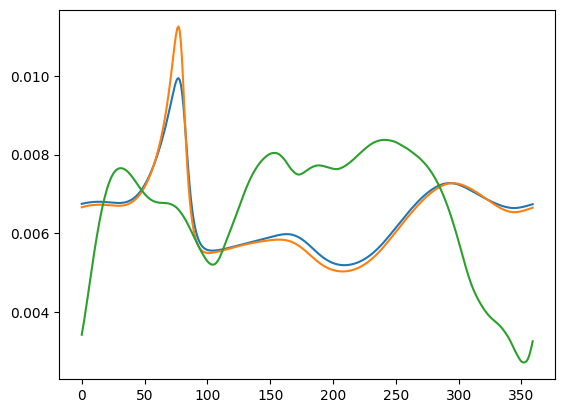

In [ ]:
plt.plot(_fit_cos_evpa_A_only(jonly_r_evpa[0]))
plt.plot(_fit_cos_evpa_A_only(jonly_r_evpa_4[0]))
plt.plot(_fit_cos_evpa_A_only(jonly_r_evpa_14[0]))

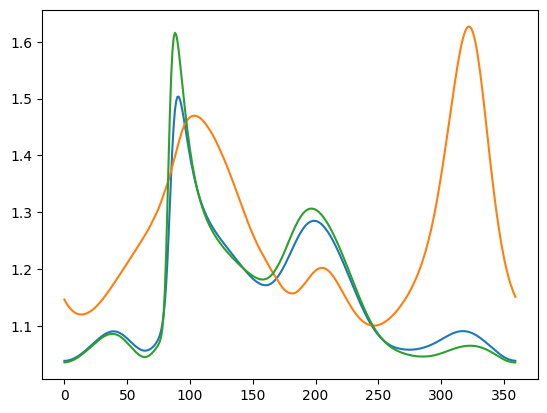

In [ ]:
plt.plot(
    _fit_cos_evpa_A_only(jonly_a_evpa[0][0]) / _fit_cos_evpa_A_only(jonly_r_evpa[0][0])
)
plt.plot(
    _fit_cos_evpa_A_only(jonly_a_evpa[10][0])
    / _fit_cos_evpa_A_only(jonly_r_evpa[10][0])
)
# plt.plot(_fit_cos_evpa_A_only(jonly_a_evpa[14][0])/_fit_cos_evpa_A_only(jonly_r_evpa[14][0]))
plt.plot(
    _fit_cos_evpa_A_only(jonly_a_evpa[4][0]) / _fit_cos_evpa_A_only(jonly_r_evpa[4][0])
)
# plt.ylim(0.9,1.1)

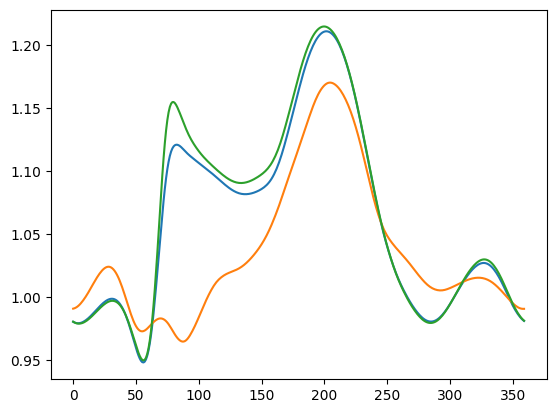

In [ ]:
plt.plot(_fit_cos_evpa_A_only(a_evpa[0][0]) / _fit_cos_evpa_A_only(r_evpa[0][0]))
plt.plot(_fit_cos_evpa_A_only(a_evpa[10][0]) / _fit_cos_evpa_A_only(r_evpa[10][0]))
plt.plot(_fit_cos_evpa_A_only(a_evpa[4][0]) / _fit_cos_evpa_A_only(r_evpa[4][0]))
# plt.ylim(0.9,1.1)

(0.9, 1.1)

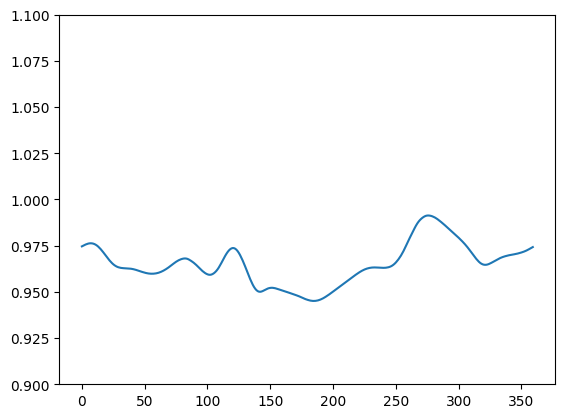

In [ ]:
plt.plot(
    _fit_cos_evpa_A_only(EVPA1600fake_1d[0])
    / _fit_cos_evpa_A_only(analytical_EVPA_fake_after_imageS_1d[0])
)
plt.ylim(0.9, 1.1)

Text(0.5, 1.0, 'EVPA (gaussian kernel=2.17), ray tracing')

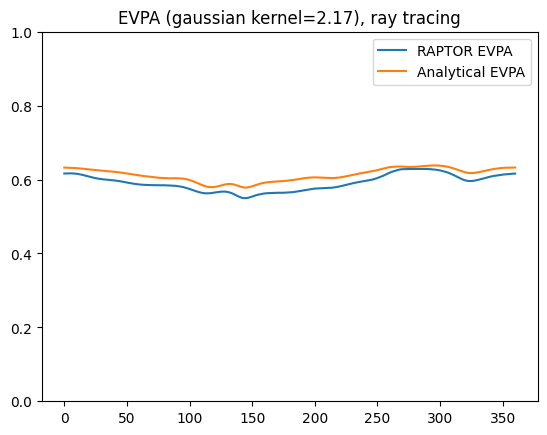

In [ ]:
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(EVPA1600fake_1d[0]) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(analytical_EVPA_fake_after_imageS_1d[0]) / np.pi * 180,
    label="Analytical EVPA",
)
plt.legend()
plt.ylim(0, 1)
plt.title("EVPA (gaussian kernel=2.17), ray tracing")

Text(0.5, 1.0, 'EVPA (gaussian kernel=2.17), ray tracing')

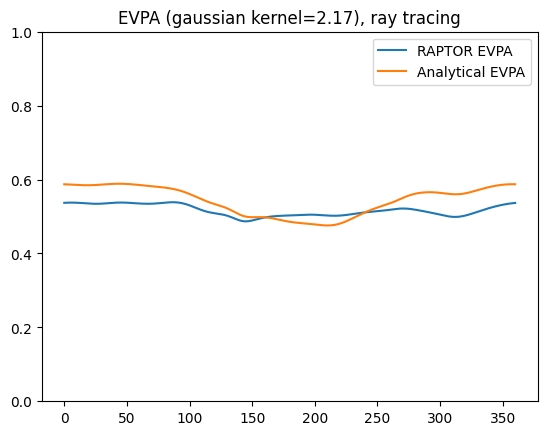

In [ ]:
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(EVPA1600fake_1d[0]) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(analytical_EVPA_fake_after_imageS_1d[0]) / np.pi * 180,
    label="Analytical EVPA",
)
plt.legend()
plt.ylim(0, 1)
plt.title("EVPA (gaussian kernel=2.17), ray tracing")

Text(0.5, 1.0, 'EVPA (gaussian kernel=0), ray tracing')

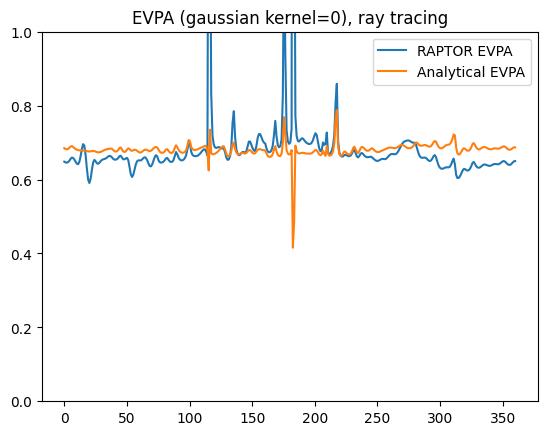

In [ ]:
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(EVPA1600fake_1d[0]) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(analytical_EVPA_fake_after_imageS_1d[0]) / np.pi * 180,
    label="Analytical EVPA",
)
plt.legend()
plt.ylim(0, 1)
plt.title("EVPA (gaussian kernel=0), ray tracing")

Text(0.5, 1.0, 'EVPA (gaussian kernel=2.17)')

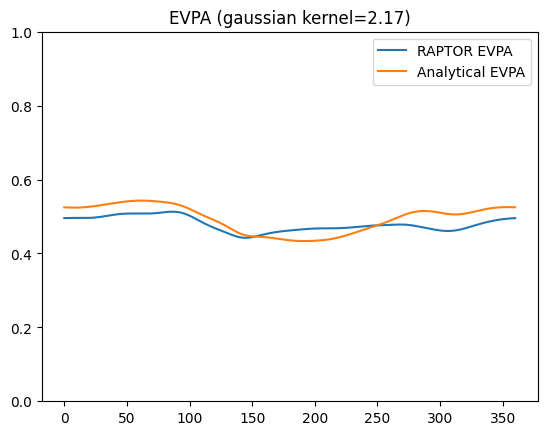

In [ ]:
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(EVPA1600fake_1d[0]) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(analytical_EVPA_fake_after_imageS_1d[0]) / np.pi * 180,
    label="Analytical EVPA",
)
plt.legend()
plt.ylim(0, 1)
plt.title("EVPA (gaussian kernel=2.17)")

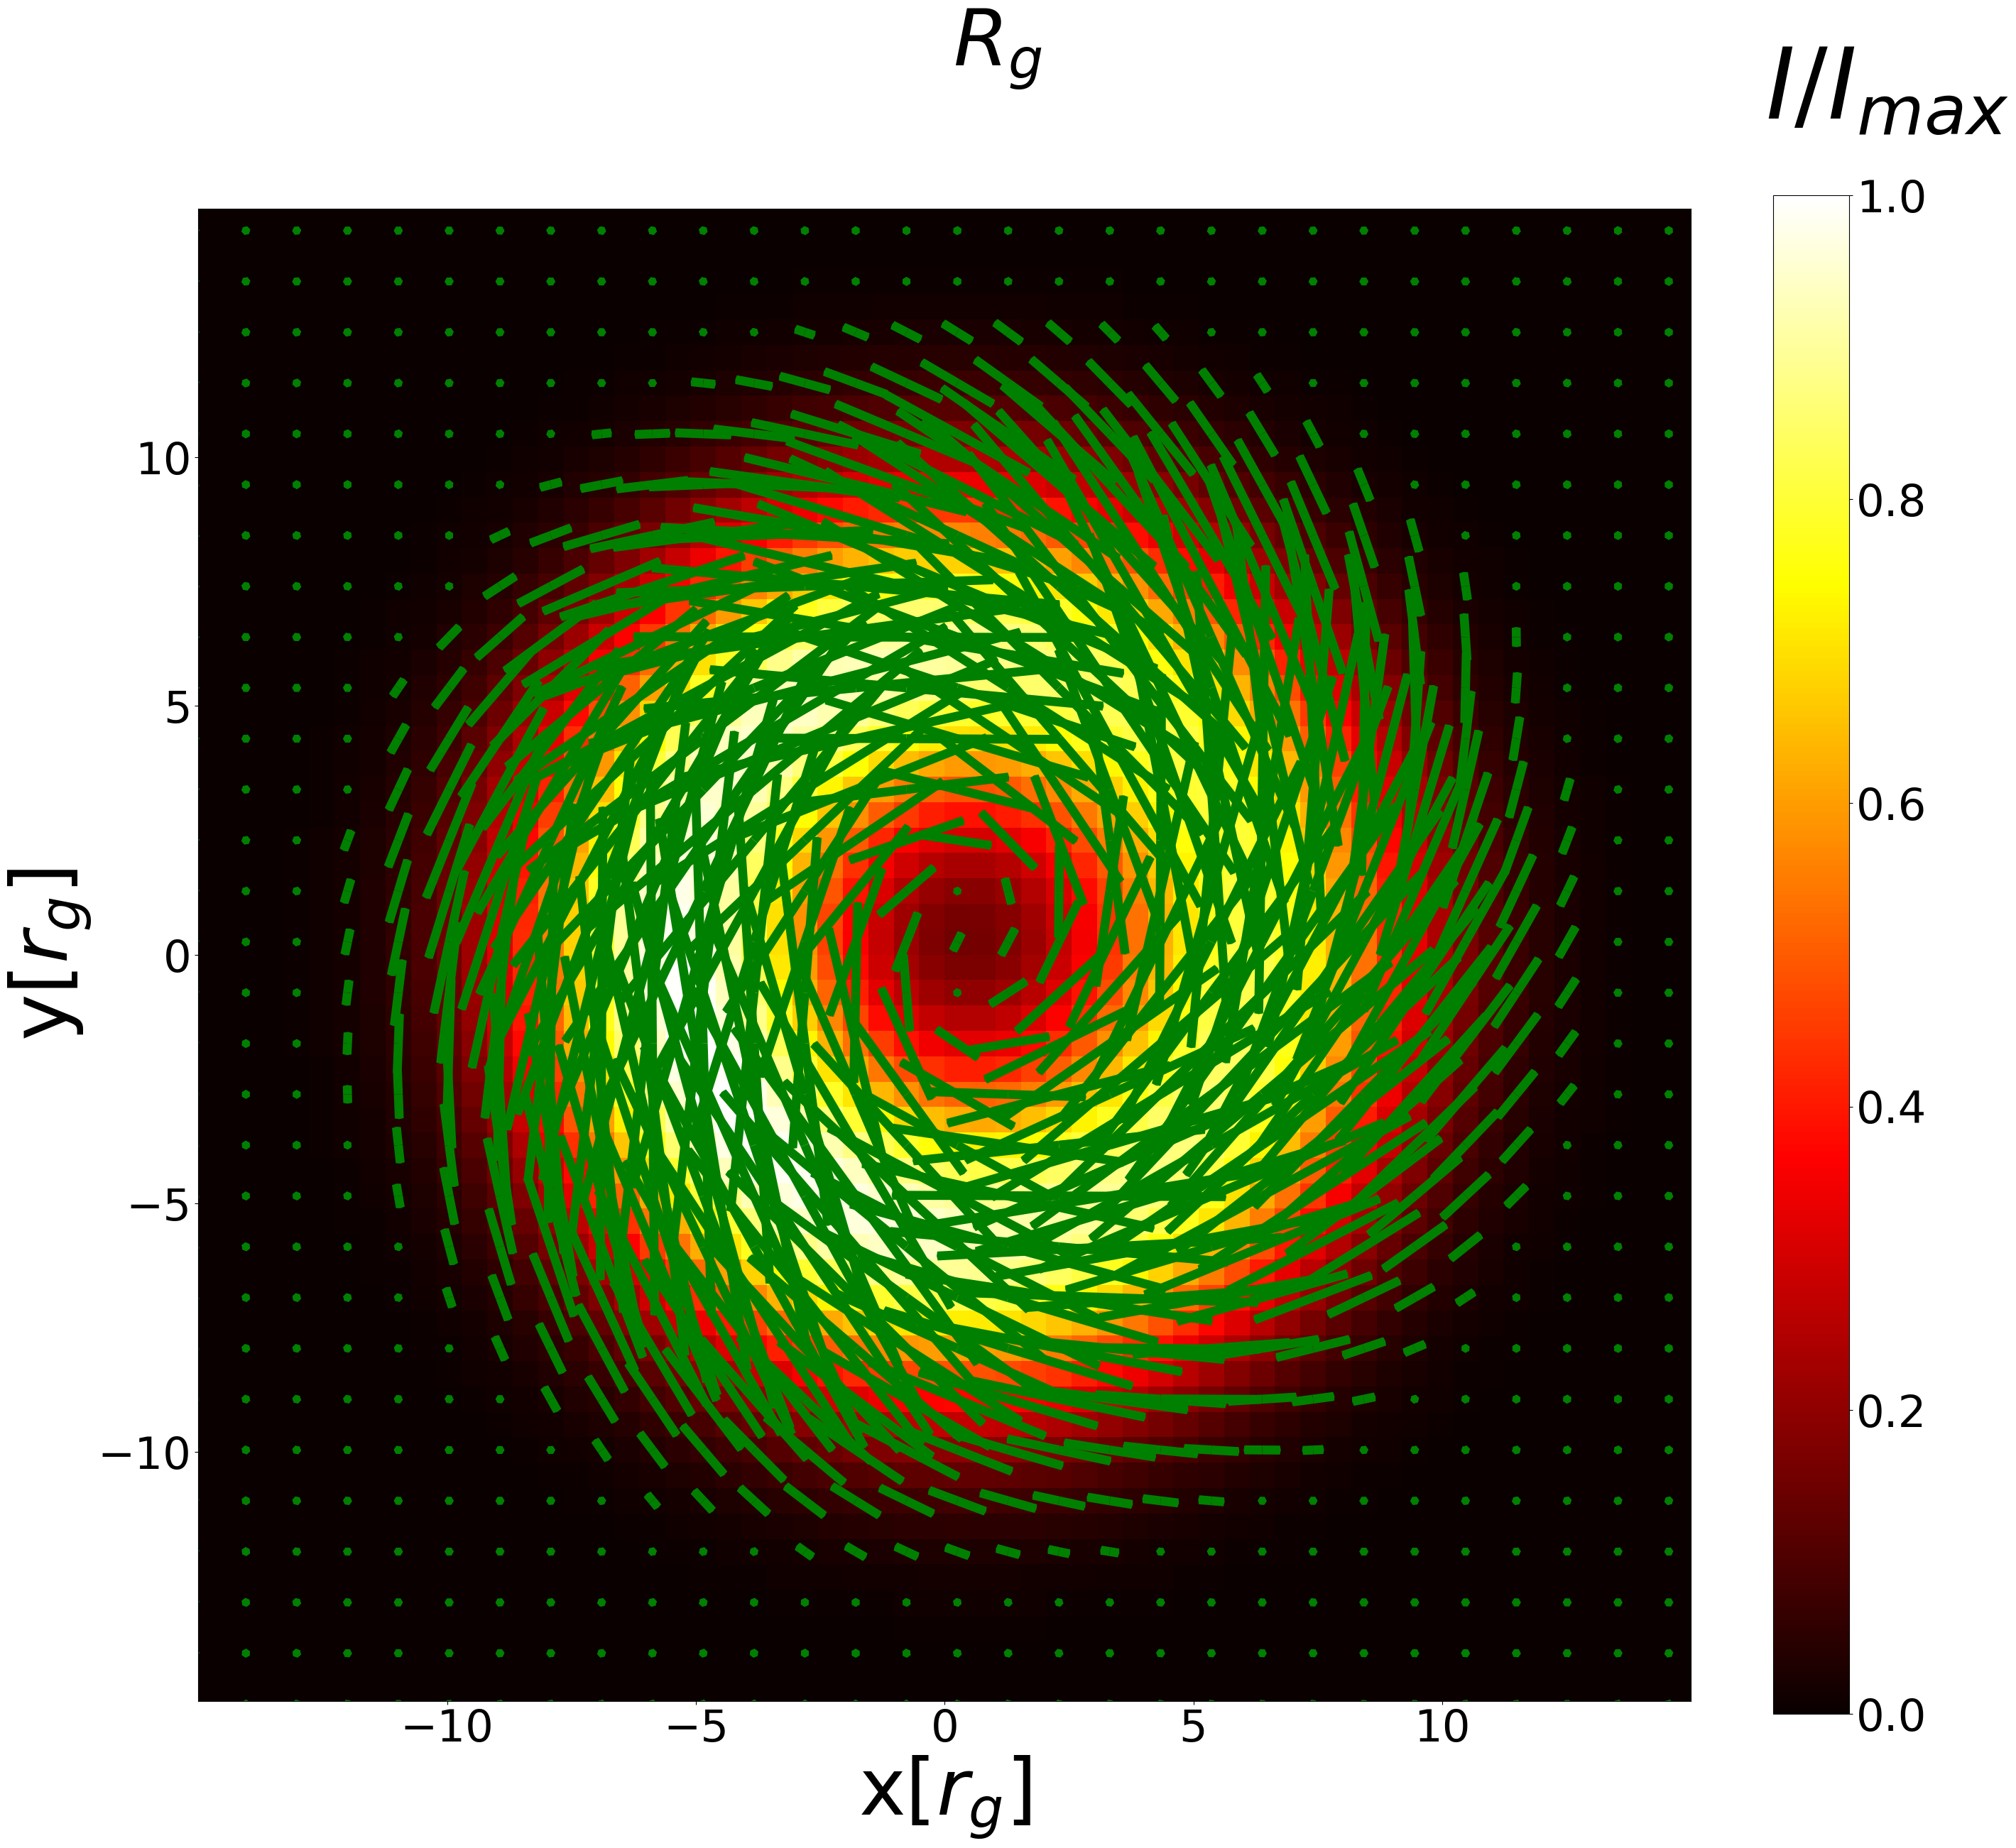

In [ ]:
%matplotlib inline
_fig,_=plot_quivers(grmhdData1600fake[0,:,:,0],(grmhdData1600fake[0,:,:,1]**2+grmhdData1600fake[0,:,:,2]**2)**0.5,0.5* np.arctan2(grmhdData1600fake[0,:,:,2],grmhdData1600fake[0,:,:,1]))
plt.show()

In [ ]:
plot_quivers(
    grmhdData1600fake[0, :, :, 0],
    (grmhdData1600fake[0, :, :, 1] ** 2 + grmhdData1600fake[0, :, :, 2] ** 2) ** 0.5,
    0.5 * np.arctan2(grmhdData1600fake[0, :, :, 2], grmhdData1600fake[0, :, :, 1]),
)

(<Figure size 3000x3000 with 2 Axes>,
 <Axes: xlabel='x[$r_g$]', ylabel='y[$r_g$]'>)

In [ ]:
grmhdData1600 = np.load("data_in/grmhdData1600.npy", allow_pickle=True)
_grmhdDataAfterImageS1600, _EVPA1600, _EVPA_1d1600, _ = getGRMHDDataAfterImageS(
    grmhdData1600[np.newaxis, ...]
)

0


In [ ]:
analytical_data = np.zeros((17, 100, 100, 4))

_tmp_EVPA = 0.5 * np.arctan2(grmhdData1600[0, :, :, 2], grmhdData1600[0, :, :, 1])
_tmp_P = np.sqrt(grmhdData1600[0, :, :, 1] ** 2 + grmhdData1600[0, :, :, 2] ** 2)
for i in range(17):
    analytical_data[i, :, :, 0] = grmhdData1600[0, :, :, 0]
    if i == 0:
        _GRMHD_EVPA_plus_Axion = _tmp_EVPA
    else:
        wt = 2 * np.pi / 16 * i
        _GRMHD_EVPA_plus_Axion = _tmp_EVPA + _axion_field(
            x_coords, y_coords, lambda r: _R(np.maximum(r - 1.5, 1)), wt
        )
    analytical_data[i, :, :, 1] = np.cos(2 * _GRMHD_EVPA_plus_Axion) * _tmp_P
    analytical_data[i, :, :, 2] = np.sin(2 * _GRMHD_EVPA_plus_Axion) * _tmp_P

(
    analytical_data_after_imageS,
    analytical_EVPA_after_imageS,
    analytical_EVPA_after_imageS_1d,
    _,
) = getGRMHDDataAfterImageS(analytical_data[np.newaxis, ...])

0


Text(0.5, 1.0, 'EVPA (gaussian kernel=0)')

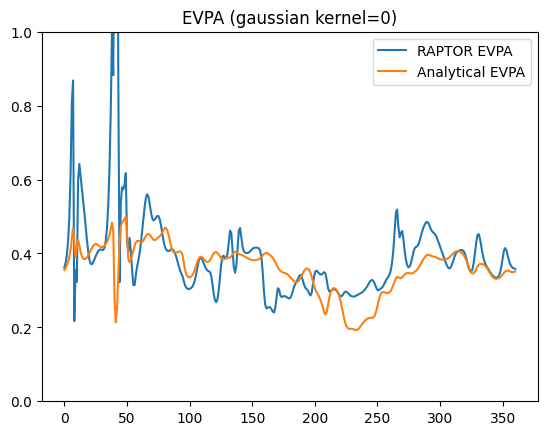

In [ ]:
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(_EVPA_1d1600[0]) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[0]) / np.pi * 180,
    label="Analytical EVPA",
)
plt.legend()
plt.ylim(0, 1)
plt.title("EVPA (gaussian kernel=0)")

analytical 的有两种算法：

1.不考虑 P 的模和辐角

2.考虑 P 的模和辐角


1.RAPTOR 结果将赤道面上 j 设为一个给定值，EVPA 转圈，r 方向取~5.5 的 gaussian，关闭其他地方效应
j 的给定值可以如下：

2.赤道面用原有 GRMHD 的结果，其他地方关闭

3.正常 RAPTOR 的结果

2x3

400 跑一个，100 跑 alpha=0.3 的 141 个


Text(0.5, 1.0, 'EVPA (whole disk) (gaussian kernel=2.17)')

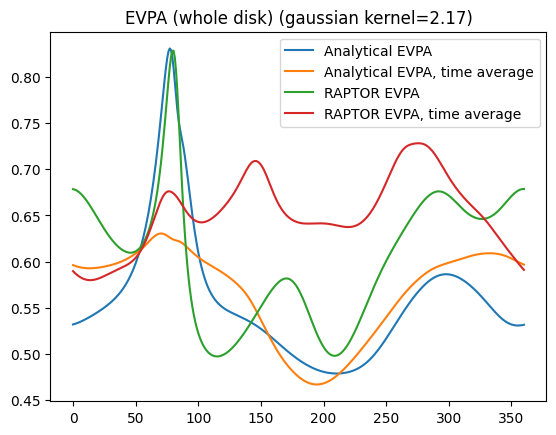

In [ ]:
# plt.plot(np.linspace(0,360,360),_analytical_A_no_blur[0:1].mean(axis=0)/np.pi*180,label='Analytical EVPA')
# plt.plot(np.linspace(0,360,360),_analytical_A_no_blur.mean(axis=0)/np.pi*180,label='Analytical EVPA, time average')
plt.plot(
    np.linspace(0, 360, 360),
    _analytical_A[0:1].mean(axis=0) / np.pi * 180,
    label="Analytical EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _analytical_A.mean(axis=0) / np.pi * 180,
    label="Analytical EVPA, time average",
)
# plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(_EVPA_1d1600[0])/np.pi*180,label='RAPTOR EVPA')
# plt.plot(np.linspace(0,360,360),_fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[0])/np.pi*180,label='Analytical EVPA')
# plt.plot(np.linspace(0,360,360),_tmp[0:1].mean(axis=0)/np.pi*180,label='RAPTOR EVPA')
# plt.plot(np.linspace(0,360,360),_tmp[:].mean(axis=0)/np.pi*180,label='RAPTOR EVPA, time average')
plt.plot(
    np.linspace(0, 360, 360),
    EVPA_fit_result_1d[0:1, :, 0].mean(axis=0) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    EVPA_fit_result_1d[:, :, 0].mean(axis=0) / np.pi * 180,
    label="RAPTOR EVPA, time average",
)
# plt.plot(np.linspace(0,360,360),_tmp[99:100].mean(axis=0)/np.pi*180)
# plt.ylim(0,1)
plt.legend()
# plt.ylim(0,1)
plt.title("EVPA (whole disk) (gaussian kernel=2.17)")

Text(0.5, 1.0, 'EVPA (gaussian kernel=2.17)')

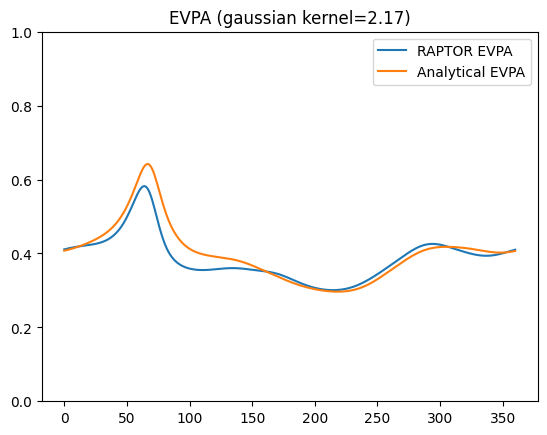

In [ ]:
# plt.plot(np.linspace(0,360,360),_analytical_A_no_blur.mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),_analytical_A.mean(axis=0)/np.pi*180)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(_EVPA_1d1600[0]) / np.pi * 180,
    label="RAPTOR EVPA",
)
plt.plot(
    np.linspace(0, 360, 360),
    _fit_cos_evpa_A_only(analytical_EVPA_after_imageS_1d[0]) / np.pi * 180,
    label="Analytical EVPA",
)
plt.legend()
plt.ylim(0, 1)
plt.title("EVPA (gaussian kernel=2.17)")
# plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[:,:,0].mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),_tmp[:].mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),EVPA_fit_result_1d[99:100,:,0].mean(axis=0)/np.pi*180)
# plt.plot(np.linspace(0,360,360),_tmp[99:100].mean(axis=0)/np.pi*180)
# plt.ylim(0,1)

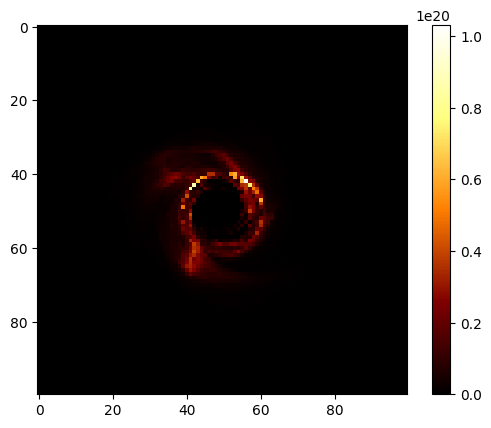

In [ ]:
plt.imshow(grmhdDataOrigin[99, 0, :, :, 0], cmap="afmhot")
plt.colorbar()

In [ ]:
analytical_data = np.zeros((100, 100, 4))
analytical_data[:, :, 0] = grmhdDataOrigin[:, 0, :, :, 0].mean(axis=0)

x_coords = np.tile(np.linspace(-49.5, 49.5, 100), (100, 1)) * 46.2262 / 99
y_coords = (
    np.tile(np.linspace(-49.5, 49.5, 100).reshape(100, 1), (1, 100)) * 46.2262 / 99
)
analytical_data[:, :, 1] = (
    np.cos(_phi_trace(x_coords, y_coords)) * analytical_data[:, :, 0]
)
analytical_data[:, :, 2] = (
    np.sin(_phi_trace(x_coords, y_coords)) * analytical_data[:, :, 0]
)
analytical_data[:, :, 3] = 0


(
    analytical_data_after_imageS,
    analytical_EVPA_after_imageS,
    analytical_EVPA_after_imageS_1d,
    _,
) = getGRMHDDataAfterImageS(analytical_data[np.newaxis, np.newaxis, ...])

0


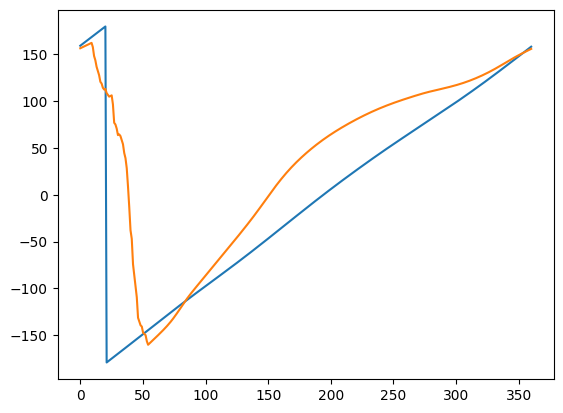

In [ ]:
_analytical_phi = (
    analytical_EVPA_after_imageS_1d[0, 0, :] / np.pi * 180 + 0.4 * 180
) * 2
_analytical_phi[_analytical_phi > 180] -= 360
plt.plot(np.linspace(0, 360, 360), _analytical_phi)
plt.plot(
    np.linspace(0, 360, 360), EVPA_fit_result_1d[:, :, 1].mean(axis=0) / np.pi * 180
)

In [ ]:
grmhdDataOrigin = np.load("data_in/grmhdDataOrigin.npy", allow_pickle=True)

_tmp = np.zeros((141, 100, 100))
for i in range(141):
    _tmp[i, :, :] = _fit_cos_evpa_A_only(
        0.5 * np.arctan2(grmhdDataOrigin[i, :, :, :, 2], grmhdDataOrigin[i, :, :, :, 1])
    )

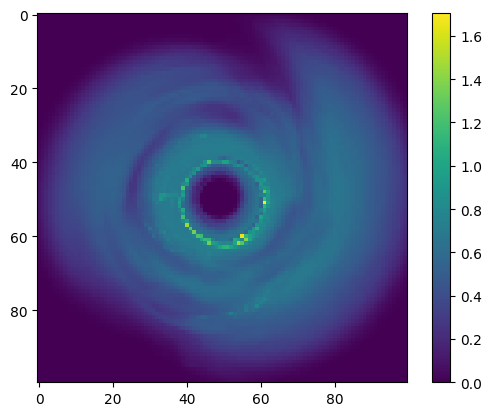

In [ ]:
plt.imshow(_tmp[:, :, :].mean(axis=0) / np.pi * 180)
plt.colorbar()
# plt.clim(0,0.1/2/np.pi/np.pi*180)

0


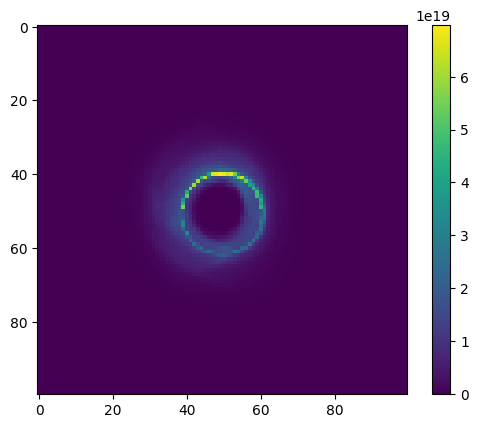

In [ ]:
plt.imshow(grmhdDataOrigin[:, 0, :, :, 0].mean(axis=0))
plt.colorbar()

In [ ]:
_EVPA_1d1600.shape

(1, 17, 360)